# Lead-k: interne Qualitätskontrolle der finalen QA-Pipeline

## Eingaben und Ausgaben

Nach der einmaligen Vorbereitung mit `python 05_analyze.py --prepare` genügt **Run All**.
Die folgende Zelle zeigt Daten, Vorgängertabellen und neue Ausgaben. `DATA_DIR` und
`OUTPUT_DIR` dürfen auf eigene absolute Verzeichnisse zeigen. `TABLES` liest standardmäßig
die vorbereiteten historischen Tabellen; für selbst neu erzeugte Vorgängertabellen
kann hier `OUTPUT_DIR / "tables"` stehen. Eingaben und neue Ausgaben bleiben getrennt.


In [1]:
from pathlib import Path
from faktenretention.paths import PROJECT_ROOT
from faktenretention.text_rules import count_words
from faktenretention.notebook_context import setup_notebook
from faktenretention.io import relative_path, sha

# Hier können eigene absolute Daten- und Ausgabeverzeichnisse stehen.
DATA_DIR = PROJECT_ROOT / "data/prepared"
OUTPUT_DIR = PROJECT_ROOT / "results/notebooks"
# Historische Vorgängertabellen; für eigene Neuberechnungen OUTPUT_DIR / "tables" einsetzen.
TABLES = DATA_DIR / "tables"
setup_notebook(DATA_DIR, OUTPUT_DIR)
OUT = OUTPUT_DIR / "tables/09_lead_k_kontrolle"
FIG = OUTPUT_DIR / "figures/09_lead_k_kontrolle"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print("Eingaben:", DATA_DIR / "qa")
print("Vorgängertabellen:", TABLES)
print("Neue Tabellen:", OUT)
print("Neue Grafiken:", FIG)


Eingaben: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/qa
Vorgängertabellen: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/tables
Neue Tabellen: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/tables/09_lead_k_kontrolle
Neue Grafiken: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/figures/09_lead_k_kontrolle


## 1. Zielsetzung und wissenschaftliche Motivation

Die Masterarbeit untersucht Faktenretention unter progressiver Kompression. Dieses
Notebook wertet ausschließlich **vorhandene Lead-k-Daten** des Hauptexperiments aus:
100 Artikel, 20 Ausgangsfakten je Artikel und vier Zielstufen (500, 300, 150, 75).
Die verschachtelten Präfixe erlauben eine interne Monotoniekontrolle und einen
evidenzbasierten Positivtest. Beides charakterisiert den **gesamten QA-Messprozess**.

**Verbindlicher Umfang:** Bestehende QA-Labels werden aus dem finalen Archiv gelesen
und unverändert ausgewertet. Keine Klassifikationskorrekturen, keine neuen Antworten,
keine LLM-Aufrufe, keine neuen Summaries und keine Bearbeitung bestehender Notebooks.
Alle Ausgaben liegen in diesem neuen, vom Abgabepaket getrennten Ordner.

Die Ergebniszusammenfassung am Ende entsteht aus den berechneten Werten. Es werden
keine unabhängigen menschlichen Urteile behauptet. Die Belegauswahl erfolgt ohne
Verwendung der beobachteten QA-Labels.

## Einordnung dieses Notebooks

**Warum diese Analyse?** Die Retentionskennzahl der Masterarbeit stammt aus einer QA-Pipeline. Bevor Verfahrensunterschiede interpretiert werden, ist zu prüfen, ob diese Messung intern plausibel reagiert. Lead-k liefert verschachtelte Artikelpräfixe: Ein kürzeres Präfix kann keine neue Information enthalten, die im längeren Präfix fehlte. Ein späterer Rückwechsel zu Retained ist deshalb ein Warnsignal für den Messprozess, kein Beweis einer verbesserten Zusammenfassung.

**Forschungsfrage:** Wie häufig widerspricht der gespeicherte QA-Verlauf dieser Struktur, und erkennt die Pipeline streng belegte Positivfälle? Der Positivtest deckt nur einen sehr kleinen, konservativ ausgewählten Teil der Fälle ab und liefert keine allgemeine Fehlerrate.

**Zusammenhang:** Notebook 10 untersucht Folgen möglicher Messfehler für die Rangfolgen. Notebook 11 untersucht tatsächliche Textlängen. Notebook 12 prüft die Übereinstimmung mit zusätzlichen LLM-Urteilen. Alle vier Untersuchungen sind ergänzende Diagnostik, keine nachträgliche Scoreroptimierung.

**Mitgelieferte Grundlage:** Die erste Codezelle zeigt die vorbereiteten Eingaben. Historische Definitionen liegen bytegleich unter `DATA_DIR/sources/`; sie dienen als Herkunftsbelege und werden nicht als Analysecode ausgeführt. Neue Tabellen stehen unter `OUTPUT_DIR/tables/`, Grafiken unter `OUTPUT_DIR/figures/`.


### Einrichtung und Reproduzierbarkeit

Benötigt: Python ≥ 3.10, pandas, NumPy, Matplotlib sowie nbformat/nbclient und
ipykernel zum Ausführen. Kein Modellzugriff und kein Netzwerkzugriff erforderlich.
Die Eingaben werden relativ zu diesem Paket unter `DATA_DIR/qa/` gelesen;
die Ausgaben liegen unter `OUTPUT_DIR/tables/09_lead_k_kontrolle/`. Der Bootstrap verwendet
10.000 Artikelstichproben und Seed 32. Die Analyse ist ein diagnostisches Notebook,
keine nachträgliche Optimierung der QA-Bewertung.

In [2]:
from pathlib import Path
from itertools import combinations
from collections import Counter
import ast, gzip, hashlib, html, importlib.util, importlib.metadata
import json, os, platform, re, sys, zipfile
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter, MaxNLocator
from IPython.display import display, Markdown, HTML

sys.dont_write_bytecode = True  # keine __pycache__-Dateien im Quellpaket
BUNDLE = DATA_DIR
PACKAGE = DATA_DIR
DATA = DATA_DIR / "qa"
VERSION = 'aktuell_20260930'
ROOT = OUT
FIG.mkdir(parents=True, exist_ok=True)
from faktenretention.protocol import STAGES
SEED, BOOTSTRAPS = 32, 10_000
FACTKEY = ['article_id', 'canonical_fact_id']
KEY = FACTKEY + ['stage_target_words']
LABELS = ['retained', 'lost', 'reference_discordant', 'technical_missing']
NON = ['lost', 'reference_discordant']
COLORS = {'retained':'#0072B2', 'lost':'#E69F00',
          'reference_discordant':'#CC79A7', 'technical_missing':'#AAAAAA'}
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':200, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.titlelocation':'left', 'axes.grid':False})
pd.set_option('display.max_rows', 28)
pd.set_option('display.max_columns', 18)

def read_table(relative):
    return pd.read_csv(DATA / relative, dtype=str, keep_default_na=False)

def export(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False, encoding='utf-8-sig')

def save_figure(fig, name):
    for ext in ['png', 'pdf', 'svg']:
        fig.savefig(FIG / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def percent(n, d):
    return 100 * n / d if d else np.nan

def de(value, digits=1):
    return f'{value:.{digits}f}'.replace('.', ',') if pd.notna(value) else 'nicht bestimmbar'

def truth(series):
    assert series.isin(['True', 'False']).all()
    return series.eq('True')

assert (DATA / 'source_manifest.json').is_file(), DATA
software = {'python': platform.python_version(), **{m: importlib.metadata.version(m)
            for m in ['numpy', 'pandas', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']}}
display(pd.Series(software, name='Version').to_frame())


,Version
python,3.13.15
numpy,2.5.4
pandas,3.0.6
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


## 2. Datenquellen und Validierung der Eingabedaten

Maßgeblich ist `aktuell_20260930`, wie im Projekt-README und im Quellenmanifest
festgelegt. Die späteren Plain-/Few-Shot-Ersetzungen betreffen Lead-k nicht.
`original_frozen` wird nicht mit der finalen Fassung vermischt.

Verwendet werden Originalartikel und kanonische Fakten aus `shared`, tatsächliche
Summaries, gespeicherte QA-Antworten und **bereits vorhandene** Bewertungsfelder aus
`scored_archived.csv.gz`. Der Scorer-Snapshot und seine Originalfunktionen werden
nur für die Nachvollziehbarkeit und diagnostische Zwischenwerte gelesen.

In [3]:
manifest_path = DATA / 'source_manifest.json'
manifest = json.loads(manifest_path.read_text())
assert manifest['default_version'] == VERSION
used_relative = [
    'shared/test_articles.csv.gz', 'shared/canonical_facts.csv.gz',
    f'{VERSION}/summaries.csv.gz', f'{VERSION}/answers.csv.gz',
    f'{VERSION}/scored_archived.csv.gz',
    f'{VERSION}/generation_states.jsonl.gz',
    'code/qa_scorer_snapshot.py', 'code/score_model_selection_batch.py',
    'code/answer_summary_questions.py',
    f'{VERSION}/provenienz/qa/merge_manifest.json',
    f'{VERSION}/provenienz/result_merge_manifest.json',
]
entries = {row['file']:row for row in manifest['files']}
source_rows = []
for relative in used_relative:
    path = DATA / relative
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    entry = entries[relative]
    assert digest == entry['sha256'], relative
    # Die State-Sammeldatei hat keine einzelne unkomprimierte Ursprungsdatei.
    if path.suffix == '.gz' and not relative.endswith('generation_states.jsonl.gz'):
        assert hashlib.sha256(gzip.decompress(path.read_bytes())).hexdigest() == entry['original_sha256']
    source_rows.append({'Datei':relative_path(path, PACKAGE), 'sha256':digest,
                        'Ursprung':entry['original_file'], 'Manifestabgleich':True})

extra_paths = [DATA_DIR / "sources/README_START.md",
              DATA_DIR / "sources/six_method_pilot_common.py",
              DATA_DIR / "sources/run_six_method_final_100.py",
              DATA_DIR / "sources/hauptexperiment_01_qa_faktenretention.quellnotebook.json",
              DATA_DIR / "sources/hauptexperiment_03_verlustmuster.quellnotebook.json"]
for path in extra_paths:
    source_rows.append({'Datei':relative_path(path, PACKAGE),
                        'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
                        'Ursprung':'Implementierung / Auswertungsdefinition', 'Manifestabgleich':False})
sources = pd.DataFrame(source_rows)
sources_before = {str(PACKAGE / r.Datei):r.sha256 for r in sources.itertuples()}
sources_before[str(manifest_path)] = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
export(sources, 'quellen_sha256')
display(sources[['Datei','Manifestabgleich']])

facts = read_table('shared/canonical_facts.csv.gz')
articles = read_table('shared/test_articles.csv.gz')
summaries_all = read_table(f'{VERSION}/summaries.csv.gz')
answers_all = read_table(f'{VERSION}/answers.csv.gz')
archived_all = read_table(f'{VERSION}/scored_archived.csv.gz')
lead = summaries_all[summaries_all.method.eq('lead_k')].copy()
answers = answers_all[answers_all.summary_prompt_variant.eq('lead_k')].copy()
archived = archived_all[archived_all.summary_prompt_variant.eq('lead_k')].copy()
for frame in [answers, archived]:
    frame['stage_target_words'] = frame.stage_target_words.astype(int)
IDS = sorted(articles.article_id, key=int)
assert len(articles) == 100 and articles.article_id.is_unique
assert len(facts) == 2000 and facts.canonical_fact_id.is_unique
assert set(facts.article_id) == set(IDS)
assert facts.groupby('article_id').size().eq(20).all()
assert len(summaries_all) == 600 and len(lead) == 100 and lead.article_id.is_unique
assert len(answers_all) == len(archived_all) == 48000
assert len(answers) == len(archived) == 8000
assert not answers.duplicated(KEY).any() and not archived.duplicated(KEY).any()
expected = {(r.article_id, r.canonical_fact_id, k) for r in facts.itertuples() for k in STAGES}
assert set(answers[KEY].itertuples(index=False, name=None)) == expected
assert set(archived[KEY].itertuples(index=False, name=None)) == expected

# Alle gespeicherten Antworten/Felder gegen das Labelarchiv prüfen; kein neues Scoring.
qa_raw_check = answers.merge(archived, on=KEY, suffixes=('_raw','_arch'), validate='one_to_one')
for field in answers.columns.difference(KEY):
    assert qa_raw_check[field+'_raw'].eq(qa_raw_check[field+'_arch']).all(), field
qa = archived.merge(facts[FACTKEY + ['fact','source_evidence','question','reference_answer','dataset_index']],
                    on=FACTKEY, validate='many_to_one', suffixes=('','_fact'))
for field in ['question', 'reference_answer', 'dataset_index']:
    assert qa[field].eq(qa[field+'_fact']).all(), field
qa = qa.drop(columns=['question_fact','reference_answer_fact','dataset_index_fact'])
long_summaries = pd.concat([lead[['article_id',f'summary_{k}']].rename(
    columns={f'summary_{k}':'summary'}).assign(stage_target_words=k) for k in STAGES], ignore_index=True)


,Datei,Manifestabgleich
0,qa/shared/test_articles.csv.gz,True
1,qa/shared/canonical_facts.csv.gz,True
2,qa/aktuell_20260930/summaries.csv.gz,True
3,qa/aktuell_20260930/answers.csv.gz,True
4,qa/aktuell_20260930/scored_archived.csv.gz,True
5,qa/aktuell_20260930/generation_states.jsonl.gz,True
6,qa/code/qa_scorer_snapshot.py,True
7,qa/code/score_model_selection_batch.py,True
8,qa/code/answer_summary_questions.py,True
9,qa/aktuell_20260930/provenienz/qa/merge_manife...,True


In [4]:
qa = qa.merge(long_summaries, on=['article_id','stage_target_words'], validate='many_to_one')
qa = qa.merge(articles[['article_id','article','article_sha256']], on='article_id', validate='many_to_one')
for r in lead.merge(articles, on='article_id', suffixes=('','_original'), validate='one_to_one').itertuples():
    assert r.article == r.article_original and r.article_sha256 == r.article_sha256_original
    assert hashlib.sha256(r.article.encode()).hexdigest() == r.article_sha256
assert qa.groupby(FACTKEY).question.nunique().eq(1).all()
assert qa.groupby(FACTKEY).reference_answer.nunique().eq(1).all()

# Gespeicherte Booleans in lesbare Zustände abbilden, ohne neu zu scoren.
qa['label'] = np.select([truth(qa.technical_missing), qa.retention.eq('True'),
                         qa.loss.eq('True'), qa.reference_discordant_answer.eq('True')],
                        ['technical_missing','retained','lost','reference_discordant'], default='INVALID')
assert qa.label.isin(LABELS).all()
qa['valid'] = qa.label.ne('technical_missing')
assert qa.valid.eq(truth(qa.analysis_eligible)).all()
assert qa.label.eq('technical_missing').eq(qa.error.ne('')).all()
assert qa.loc[~qa.valid, ['retention','loss','reference_discordant_answer']].eq('').all().all()
assert qa.loc[qa.valid, 'answer'].str.strip().ne('').all()

coverage = pd.DataFrame({'Einheit':['Artikel','Ausgangsfakten','Lead-k-Texte','QA-Positionen'],
                        'Soll':[100,2000,400,8000],
                        'Ist':[len(articles),len(facts),len(long_summaries),len(qa)]})
display(coverage)
export(coverage, 'eingabeabdeckung')
label_counts = qa.groupby(['stage_target_words','label']).size().unstack(fill_value=0).reindex(STAGES)
display(label_counts.reindex(columns=LABELS, fill_value=0))
export(label_counts.reset_index(), 'unveraenderte_qa_labels_anzahlen')


,Einheit,Soll,Ist
0,Artikel,100,100
1,Ausgangsfakten,2000,2000
2,Lead-k-Texte,400,400
3,QA-Positionen,8000,8000


label,retained,lost,reference_discordant,technical_missing
stage_target_words,,,,
500,1508,400,87,5
300,986,911,100,3
150,604,1286,107,3
75,346,1566,87,1


### Wortregel, Präfixe und finale Scorer-Konfiguration

Die tatsächliche Wortregel lautet `re.finditer(r"\b\w+\b", text)`; Lead-k schneidet
am Ende des k-ten Regex-Wortes ab, einschließlich der davorliegenden Interpunktion.
Das ist keine Whitespace-Tokenisierung. Hier wird ausschließlich geprüft, ob die
gespeicherten Texte dieser Regel und den gespeicherten Generierungszuständen entsprechen.
Die berechneten Prüffragmente ersetzen keine Daten.

Der finale Scorer ist **mehr als Token-F1 ≥ 0,5**: Er akzeptiert zuerst normalisierte
Teilstringbeziehungen, dann F1 ≥ 0,5, anschließend kanonisierte Teilstrings und unter
Längenrestriktionen kanonisierten F1 ≥ 0,43. Die Belegprüfung verlangt zusammenhängenden
Text nach Whitespace-Normalisierung und `casefold()`. Ein Fehlerbeleg wird technisch
ausgeschlossen. Der Scorer-Snapshot wird gegen die AST-Funktionskörper des vollständigen
Originalcodes geprüft; es werden keine bestehenden Labels ersetzt.

In [5]:
from faktenretention import scoring as scorer
full_source = (DATA / 'code/score_model_selection_batch.py').read_text()
snapshot_source = (DATA / 'code/qa_scorer_snapshot.py').read_text()
answer_source = (DATA / 'code/answer_summary_questions.py').read_text()

def function_ast(source, name):
    nodes = [n for n in ast.parse(source).body if isinstance(n, ast.FunctionDef) and n.name == name]
    assert len(nodes) == 1, name
    return ast.dump(nodes[0], include_attributes=False)

for name in ['normalize','token_f1','retained','canonicalize_for_retention','retention_token_f1']:
    assert function_ast(snapshot_source, name) == function_ast(full_source, name), name
assert function_ast(snapshot_source, 'support_is_grounded') == function_ast(answer_source, 'support_is_grounded')
from faktenretention.text_rules import lead_k as prefix_function


prefix_rows = []
for row in lead.itertuples():
    previous = row.article
    for stage in STAGES:
        text = getattr(row, f'summary_{stage}')
        prefix_rows.append({'article_id':row.article_id, 'stage_target_words':stage,
            'n_words':count_words(text),
            'equals_original_rule':text == prefix_function(row.article, stage),
            'nested_in_previous':previous.startswith(text), 'nonempty':bool(text.strip())})
        previous = text
prefix_audit = pd.DataFrame(prefix_rows)
assert prefix_audit[['equals_original_rule','nested_in_previous','nonempty']].all().all()
assert prefix_audit.n_words.eq(prefix_audit.stage_target_words).all()
with gzip.open(DATA / VERSION / 'generation_states.jsonl.gz', 'rt') as stream:
    lead_states = [r for line in stream if (r := json.loads(line))['method']=='lead_k']
assert len(lead_states) == 100
summary_lookup = lead.set_index('article_id')
for record in lead_states:
    row = summary_lookup.loc[str(record['article_id'])]
    state = record['state']
    assert state['complete'] and state['source_sha256'] == row.article_sha256
    assert [s['target_words'] for s in state['stages']] == STAGES
    previous = row.article
    for stage in state['stages']:
        assert stage['input_text'] == previous
        assert stage['selected']['response'] == row[f"summary_{stage['target_words']}"]
        previous = stage['selected']['response']
qa['support_grounded_diagnostic'] = [scorer.support_is_grounded(s,a,e)
    for s,a,e in zip(qa.summary, qa.answer, qa.support)]
assert qa.loc[qa.valid, 'support_grounded_diagnostic'].all()
export(prefix_audit, 'lead_k_praefixpruefung')
display(prefix_audit.groupby('stage_target_words')[['equals_original_rule','nested_in_previous','nonempty']].sum().reindex(STAGES))

availability = pd.DataFrame([
    ['Originalartikel / 2.000 Fakten / Fragen / Referenzen','vollständig vorhanden'],
    ['400 tatsächliche Lead-k-Texte / finale QA-Labels','vollständig vorhanden'],
    ['Finale QA-Antwort und Antwortbeleg','vorhanden, auch bei technischen Fehlwerten'],
    ['Finaler Scorer nach Kalibrierung','vollständiger Code und geprüfter Funktionsauszug vorhanden'],
    ['Zwischenwerte','gespeicherter maximaler F1; roher/kanonisierter F1 hier diagnostisch berechnet'],
    ['Frühere QA-Versuche / Transportverläufe','nicht als vollständiger Fallverlauf ausgewertet'],
    ['Unabhängige Humanurteile zum finalen Lead-k-Positivsatz','nicht vorhanden; keine erzeugt'],
], columns=['Information','Verfügbarkeit / Grenze'])
display(availability)
export(availability, 'datenverfuegbarkeit')


,equals_original_rule,nested_in_previous,nonempty
stage_target_words,,,
500,100,100,100
300,100,100,100
150,100,100,100
75,100,100,100


,Information,Verfügbarkeit / Grenze
0,Originalartikel / 2.000 Fakten / Fragen / Refe...,vollständig vorhanden
1,400 tatsächliche Lead-k-Texte / finale QA-Labels,vollständig vorhanden
2,Finale QA-Antwort und Antwortbeleg,"vorhanden, auch bei technischen Fehlwerten"
3,Finaler Scorer nach Kalibrierung,vollständiger Code und geprüfter Funktionsausz...
4,Zwischenwerte,gespeicherter maximaler F1; roher/kanonisierte...
5,Frühere QA-Versuche / Transportverläufe,nicht als vollständiger Fallverlauf ausgewertet
6,Unabhängige Humanurteile zum finalen Lead-k-Po...,nicht vorhanden; keine erzeugt


## 3. Analyse A: Monotonieprüfung

Ein beobachtetes `lost` oder `reference_discordant` im längeren Text und `retained`
im kürzeren Text ist ein auffälliger Rückwechsel. Fehlwerte zählen nicht als Verlust.
Die Primäranalyse verwendet auswertbare **benachbarte Paare**; ergänzend werden alle
sechs geordneten Stufenpaare geprüft. Ein geeigneter Verlauf hat mindestens ein
auswertbares Paar der jeweiligen Definition. Vollständig bedeutet vier gültige Urteile;
teilweise auswertbar bedeutet ein bis drei gültige Urteile. Technische Fehlwerte werden
nicht interpoliert. Widerspruchszahlen bezeichnen je nach Tabelle Übergänge oder
einmalig gezählte Faktenverläufe.

In [6]:
paths = qa.pivot(index=FACTKEY, columns='stage_target_words', values='label').reindex(columns=STAGES)
assert len(paths) == 2000 and paths.notna().all().all()
paths['n_valid'] = paths[STAGES].ne('technical_missing').sum(axis=1)
paths['complete'] = paths.n_valid.eq(4)
pair_rows = []
for before, after in combinations(STAGES, 2):
    columns = KEY + ['label','answer','support','question','reference_answer','source_evidence']
    paired = qa.loc[qa.stage_target_words.eq(before), columns].merge(
        qa.loc[qa.stage_target_words.eq(after), columns], on=FACTKEY,
        suffixes=('_before','_after'), validate='one_to_one')
    paired['before'], paired['after'] = before, after
    paired['transition'] = f'{before}→{after}'
    paired['adjacent'] = STAGES.index(after) - STAGES.index(before) == 1
    paired['eligible'] = paired.label_before.ne('technical_missing') & paired.label_after.ne('technical_missing')
    paired['violation'] = paired.eligible & paired.label_before.isin(NON) & paired.label_after.eq('retained')
    pair_rows.append(paired)
pairs = pd.concat(pair_rows, ignore_index=True)
adjacent = pairs[pairs.adjacent].copy()
for name, frame in [('adjacent',adjacent),('all_pairs',pairs)]:
    eligible_keys = pd.MultiIndex.from_frame(frame.loc[frame.eligible, FACTKEY].drop_duplicates())
    violation_keys = pd.MultiIndex.from_frame(frame.loc[frame.violation, FACTKEY].drop_duplicates())
    paths[f'eligible_{name}'] = paths.index.isin(eligible_keys)
    paths[f'violation_{name}'] = paths.index.isin(violation_keys)
path_counts = pd.DataFrame([
    {'Gruppe':label, 'n':int(mask.sum()), 'Nenner':len(paths), 'Prozent':percent(mask.sum(),len(paths))}
    for label, mask in [
        ('Vollständig auswertbar',paths.complete),
        ('Teilweise auswertbar (1–3 Urteile)',paths.n_valid.between(1,3)),
        ('Ohne auswertbares Urteil',paths.n_valid.eq(0)),
        ('Geeignet: mindestens ein benachbartes Paar',paths.eligible_adjacent),
        ('Geeignet: mindestens ein beliebiges Paar',paths.eligible_all_pairs)]])
display(path_counts.round(2))
export(path_counts, 'auswertbare_faktenverlaeufe')
transition_summary = adjacent.groupby(['before','after','transition'], sort=False).agg(
    n_expected=('eligible','size'), n_eligible=('eligible','sum'),
    n_violations=('violation','sum')).reset_index()
transition_summary['n_excluded_technical'] = transition_summary.n_expected - transition_summary.n_eligible
transition_summary['violation_percent'] = 100 * transition_summary.n_violations / transition_summary.n_eligible
transition_summary['n_articles_affected'] = [adjacent.loc[adjacent.transition.eq(t)&adjacent.violation,'article_id'].nunique()
                                             for t in transition_summary.transition]
display(transition_summary.round(2))
export(transition_summary, 'monotonie_benachbarte_uebergaenge')
allpair_summary = pairs.groupby(['before','after','transition'], sort=False).agg(
    n_eligible=('eligible','sum'), n_violations=('violation','sum')).reset_index()
allpair_summary['violation_percent'] = 100*allpair_summary.n_violations/allpair_summary.n_eligible
export(allpair_summary, 'monotonie_alle_stufenpaare')
combos = adjacent[adjacent.violation].groupby(['transition','label_before','label_after'], sort=False).size().rename('n').reset_index()
display(combos)
export(combos, 'monotonie_beteiligte_labelkombinationen')
problem_paths = paths[paths.violation_all_pairs].reset_index()
problem_keys = problem_paths[FACTKEY]
problem_long = qa.merge(problem_keys, on=FACTKEY, validate='many_to_one')
export(problem_long[KEY+['question','reference_answer','fact','source_evidence','label','answer','support','error']],
       'problematische_fakten_alle_stufen')
export(pairs[pairs.violation], 'widerspruechliche_stufenpaare')
export(paths.reset_index(), 'alle_faktenverlaeufe')
articles_affected = paths.reset_index().groupby('article_id').agg(
    n_paths_adjacent=('violation_adjacent','sum'), n_paths_all_pairs=('violation_all_pairs','sum')).reindex(IDS)
articles_affected['n_adjacent_violations'] = adjacent[adjacent.violation].groupby('article_id').size().reindex(IDS,fill_value=0)
export(articles_affected.reset_index(), 'monotonie_verteilung_alle_artikel')
article_distribution = articles_affected.n_paths_adjacent.value_counts().sort_index().rename_axis('n_betroffene_fakten').rename('n_artikel').reset_index()
display(article_distribution)
export(article_distribution, 'monotonie_artikelverteilung')
n_bad = int(paths.violation_adjacent.sum())
n_bad_all = int(paths.violation_all_pairs.sum())
n_complete_bad = int((paths.complete & paths.violation_all_pairs).sum())
n_affected_articles = int(articles_affected.n_paths_adjacent.gt(0).sum())
display(Markdown(f'**Benachbart:** {n_bad}/{int(paths.eligible_adjacent.sum())} geeignete Faktenverläufe '
    f'({de(percent(n_bad,paths.eligible_adjacent.sum()))} %) mit mindestens einem Rückwechsel; '
    f'{int(adjacent.violation.sum())} widersprüchliche Übergänge in {n_affected_articles} Artikeln. '
    f'**Alle Paare:** {n_bad_all}/{int(paths.eligible_all_pairs.sum())} Verläufe.'))


,Gruppe,n,Nenner,Prozent
0,Vollständig auswertbar,1991,2000,99.55
1,Teilweise auswertbar (1–3 Urteile),9,2000,0.45
2,Ohne auswertbares Urteil,0,2000,0.00
3,Geeignet: mindestens ein benachbartes Paar,1999,2000,99.95
4,Geeignet: mindestens ein beliebiges Paar,1999,2000,99.95


,before,after,transition,n_expected,n_eligible,n_violations,n_excluded_technical,violation_percent,n_articles_affected
0,500,300,500→300,2000,1994,10,6,0.50,9
1,300,150,300→150,2000,1994,9,6,0.45,9
2,150,75,150→75,2000,1996,4,4,0.20,4


,transition,label_before,label_after,n
0,500→300,reference_discordant,retained,8
1,500→300,lost,retained,2
2,300→150,reference_discordant,retained,6
3,300→150,lost,retained,3
4,150→75,lost,retained,2
5,150→75,reference_discordant,retained,2


,n_betroffene_fakten,n_artikel
0,0,79
1,1,20
2,2,1


**Benachbart:** 22/1999 geeignete Faktenverläufe (1,1 %) mit mindestens einem Rückwechsel; 23 widersprüchliche Übergänge in 21 Artikeln. **Alle Paare:** 22/1999 Verläufe.

### Ergänzende Grafik: Welche Labels wechseln bei der Kürzung?

Jede Matrix umfasst dieselben 2.000 Faktenverläufe. Die Farbe zeigt den Anteil innerhalb des Ausgangslabels (Zeile); jede Zelle nennt zusätzlich die absolute Fallzahl. Technische Fehlwerte bleiben eine eigene Kategorie. Umrandet sind Rückwechsel von `lost` oder `reference_discordant` zu `retained`; sie sind Inkonsistenzhinweise, keine bewiesenen Fehlurteile.

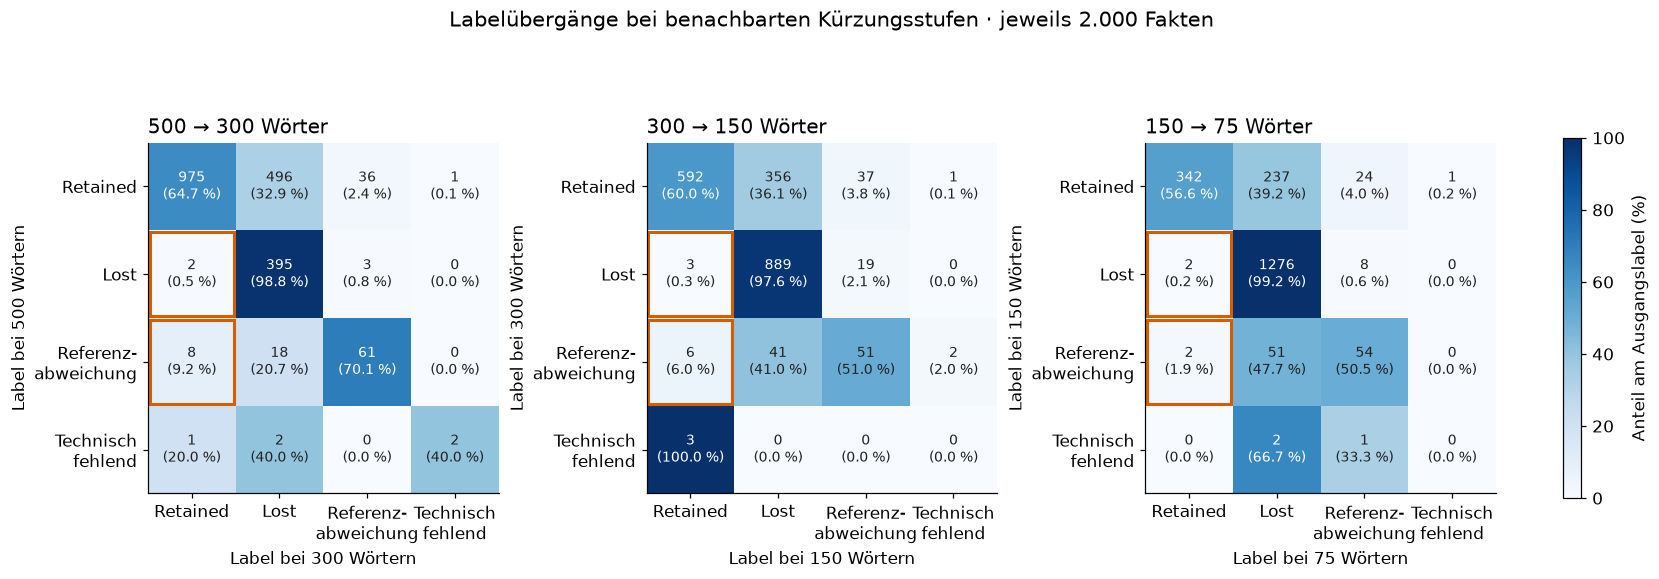

**Beobachtung:** Insgesamt 23 benachbarte Übergänge wechseln von Lost oder Referenzabweichung zu Retained. Sie betreffen 22 unterschiedliche Faktenverläufe; dieselben Fakten können in mehreren Matrizen auftreten.

In [7]:
from matplotlib.patches import Rectangle
transition_plot_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), layout='constrained')
short_labels = ['Retained', 'Lost', 'Referenz-\nabweichung', 'Technisch\nfehlend']
for ax, (before, after) in zip(axes, zip(STAGES[:-1], STAGES[1:])):
    sub = adjacent[adjacent.before.eq(before) & adjacent.after.eq(after)]
    counts = pd.crosstab(sub.label_before, sub.label_after).reindex(index=LABELS, columns=LABELS, fill_value=0)
    totals = counts.sum(axis=1)
    rates = counts.div(totals.replace(0, np.nan), axis=0)*100
    im = ax.imshow(np.ma.masked_invalid(rates.to_numpy()), vmin=0, vmax=100, cmap='Blues')
    for i, first in enumerate(LABELS):
        for j, second in enumerate(LABELS):
            n, rate = int(counts.iloc[i,j]), rates.iloc[i,j]
            text = f'{n}\n({rate:.1f} %)' if pd.notna(rate) else '0\n(kein Nenner)'
            ax.text(j, i, text, ha='center', va='center', fontsize=9,
                    color='white' if pd.notna(rate) and rate>55 else '#222222')
            transition_plot_rows.append(dict(before=before, after=after, label_before=first,
                label_after=second, n=n, denominator=int(totals.iloc[i]), row_percent=rate))
            if first in NON and second=='retained':
                ax.add_patch(Rectangle((j-.48,i-.48),.96,.96,fill=False,edgecolor='#D55E00',lw=2))
    assert counts.to_numpy().sum()==2000
    ax.set(xticks=range(4), xticklabels=short_labels, yticks=range(4), yticklabels=short_labels,
           xlabel=f'Label bei {after} Wörtern', ylabel=f'Label bei {before} Wörtern', title=f'{before} → {after} Wörter')
fig.colorbar(im, ax=axes, shrink=.65, label='Anteil am Ausgangslabel (%)')
fig.suptitle('Labelübergänge bei benachbarten Kürzungsstufen · jeweils 2.000 Fakten', fontsize=14)
export(pd.DataFrame(transition_plot_rows), 'grafik_labeluebergaenge_zeilenanteile')
save_figure(fig, 'C_labeluebergaenge_je_kuerzungsstufe')
display(Markdown(f'**Beobachtung:** Insgesamt {int(adjacent.violation.sum())} benachbarte Übergänge wechseln von '
    f'Lost oder Referenzabweichung zu Retained. Sie betreffen {n_bad} unterschiedliche Faktenverläufe; '
    'dieselben Fakten können in mehreren Matrizen auftreten.'))


### Plausibilitätsprüfung der Zahl 21

Zusätzlich zur Paarprüfung wird die Definition des vorhandenen Verlustmuster-Notebooks
nachgerechnet: Die erste beobachtete Nicht-Retained-Stufe muss bestimmbar sein;
ein technischer Fehlwert vor ihr macht diese erste Stufe unbestimmt. Ein späteres
Retained-Label zählt dann für die historische Persistenztabelle nicht mit.
Die betreffenden **Quelllabels werden auch hier unverändert verwendet**.

In [8]:
def historical_return(sequence):
    first = next((i for i,x in enumerate(sequence) if x in NON), None)
    observed = first is not None and 'retained' in sequence[first+1:]
    first_known = first is not None and 'technical_missing' not in sequence[:first]
    return observed, first_known, bool(observed and first_known)

historical = [historical_return(seq) for seq in paths[STAGES].itertuples(index=False,name=None)]
paths[['observed_return_any','first_nonretained_known','historical_counted_return']] = historical
definitions = pd.DataFrame([
    {'Definition':'Benachbart, mindestens ein gültiges Paar', 'n_verlaeufe':n_bad,
     'n_geeignet':int(paths.eligible_adjacent.sum())},
    {'Definition':'Alle sechs Stufenpaare', 'n_verlaeufe':n_bad_all,
     'n_geeignet':int(paths.eligible_all_pairs.sum())},
    {'Definition':'Vollständige Verläufe, alle Stufenpaare', 'n_verlaeufe':n_complete_bad,
     'n_geeignet':int(paths.complete.sum())},
    {'Definition':'Historische Persistenz: erste Nicht-R-Stufe bestimmbar, vor 75',
     'n_verlaeufe':int(paths.historical_counted_return.sum()),
     'n_geeignet':sum(historical_return(seq)[1] and any(x in NON for x in seq[:-1])
                       for seq in paths[STAGES].itertuples(index=False,name=None))},
])
definitions['Prozent'] = 100*definitions.n_verlaeufe/definitions.n_geeignet
display(definitions.round(2))
export(definitions, 'abgleich_21_definitionen')
additional = paths[paths.violation_all_pairs & ~paths.historical_counted_return].reset_index()
display(additional[FACTKEY+STAGES])
export(additional, 'zusatzfaelle_gegenueber_historischer_definition')
reported_21_reproduced = int(paths.historical_counted_return.sum()) == 21
display(Markdown(f'**Die berichtete Zahl 21 ist unter der historischen Definition '
    f'{"reproduzierbar" if reported_21_reproduced else "nicht reproduzierbar"}.** '
    f'Die vollständige Paarprüfung findet {n_bad_all} Verläufe. '
    'Die Differenz betrifft ausschließlich Verläufe mit technischen Fehlwerten vor der ersten '
    'beobachteten Nicht-Retained-Stufe; ein vorhandener späterer Widerspruch bleibt in der Paarprüfung sichtbar. '
    'Die Zahlen messen unterschiedliche Auswahlregeln, keine korrigierten Labels.'))


,Definition,n_verlaeufe,n_geeignet,Prozent
0,"Benachbart, mindestens ein gültiges Paar",22,1999,1.10
1,Alle sechs Stufenpaare,22,1999,1.10
2,"Vollständige Verläufe, alle Stufenpaare",21,1991,1.05
3,Historische Persistenz: erste Nicht-R-Stufe be...,21,1407,1.49


stage_target_words,article_id,canonical_fact_id,500,300,150,75
0,94,94_F03,technical_missing,lost,retained,lost


**Die berichtete Zahl 21 ist unter der historischen Definition reproduzierbar.** Die vollständige Paarprüfung findet 22 Verläufe. Die Differenz betrifft ausschließlich Verläufe mit technischen Fehlwerten vor der ersten beobachteten Nicht-Retained-Stufe; ein vorhandener späterer Widerspruch bleibt in der Paarprüfung sichtbar. Die Zahlen messen unterschiedliche Auswahlregeln, keine korrigierten Labels.

### Labelverläufe und Verteilung der Widersprüche

Die kompakte Musteransicht zeigt die betroffenen Verläufe; sämtliche Muster aller
2.000 Verläufe und alle einzelnen betroffenen Fakten sind vollständig exportiert.
Die Artikelverteilung enthält auch die Artikel ohne Widerspruch.

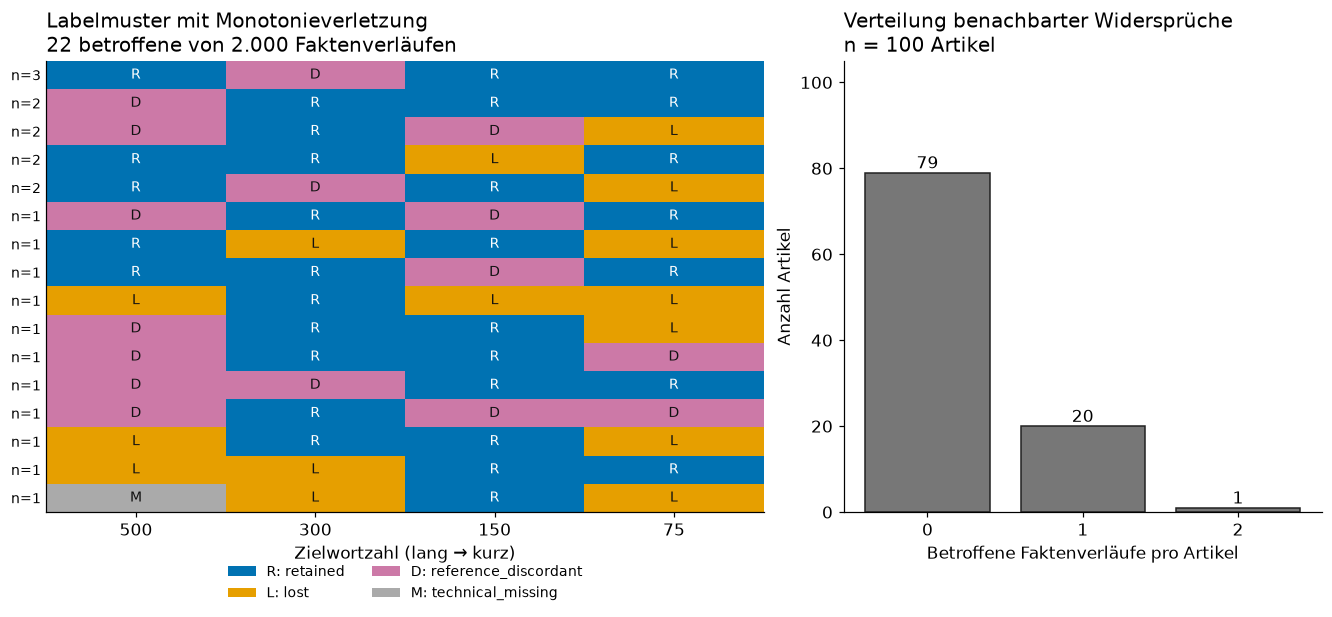

In [9]:
patterns = paths.groupby(STAGES, sort=False).size().rename('n').reset_index().sort_values('n',ascending=False)
patterns['violation'] = [any(seq[i] in NON and seq[j]=='retained' for i,j in combinations(range(4),2))
                         for seq in patterns[STAGES].itertuples(index=False,name=None)]
export(patterns, 'labelverlauf_muster')
plot_patterns = patterns[patterns.violation].copy()
if plot_patterns.empty:
    plot_patterns = patterns.head(1).copy()
mapping = {label:i for i,label in enumerate(LABELS)}
fig, (ax, bx) = plt.subplots(1,2, figsize=(12, max(5.5, len(plot_patterns)*.3)),
                            gridspec_kw={'width_ratios':[3,2]}, layout='constrained')
matrix = plot_patterns[STAGES].replace(mapping).to_numpy(dtype=int)
ax.imshow(matrix, cmap=ListedColormap([COLORS[l] for l in LABELS]),
          norm=BoundaryNorm(np.arange(-.5,4.5),4), aspect='auto')
short = {'retained':'R','lost':'L','reference_discordant':'D','technical_missing':'M'}
for i,row in enumerate(plot_patterns.itertuples(index=False,name=None)):
    for j,label in enumerate(row[:4]):
        ax.text(j,i,short[label],ha='center',va='center',fontsize=9,
                color='white' if label=='retained' else '#111111')
ax.set(xticks=range(4),xticklabels=STAGES, xlabel='Zielwortzahl (lang → kurz)',
       yticks=range(len(plot_patterns)), yticklabels=[f'n={n}' for n in plot_patterns.n])
ax.set_title(f'Labelmuster mit Monotonieverletzung\n{n_bad_all} betroffene von 2.000 Faktenverläufen')
ax.tick_params(axis='y',length=0,labelsize=9)
ax.legend(handles=[Patch(facecolor=COLORS[l],label=f'{short[l]}: {l}') for l in LABELS],
          loc='upper center',bbox_to_anchor=(.5,-.09),ncol=2,fontsize=9,frameon=False)
bx.bar(article_distribution.n_betroffene_fakten.astype(str),article_distribution.n_artikel,
       color='#777777',edgecolor='#222222')
for x,n in enumerate(article_distribution.n_artikel): bx.text(x,n+1,str(n),ha='center')
bx.set(xlabel='Betroffene Faktenverläufe pro Artikel',ylabel='Anzahl Artikel',ylim=(0,105))
bx.set_title('Verteilung benachbarter Widersprüche\nn = 100 Artikel')
save_figure(fig, 'A_labelverlaeufe_und_artikelverteilung')


## 4. Analyse B: evidenzbasierter Positivtest

### Explizite, labelunabhängige Prüfregeln

**Keine semantische Ground Truth wird rekonstruiert.** Eine vollständige Belegstelle
mit einem Antwortwort genügt hier nicht für die strenge Gruppe. Es werden zwei
verschiedene Textnormalisierungen des vorhandenen Codes verwendet:

1. **Belegtreue:** vollständiger zusammenhängender Beleg nach ausschließlich
   Whitespace-Normalisierung und `casefold()`, wie in der originalen Belegprüfung.
   Der Beleg muss genau einmal im Originalartikel und genau einmal im Lead-k-Text
   vorkommen. Keine Ellipsen, Fuzzy-Suche oder Teilbelege als Ersatz.
2. **Aussage und Antwort:** die **vollständige gespeicherte atomare Faktenaussage**
   muss zusätzlich nach der bestehenden Scorer-Normalisierung als zusammenhängende
   Wortfolge im Beleg stehen. Die vollständige Referenz muss als Wortfolge in dieser
   Aussage und im Beleg vorkommen, dort eindeutig. Wegen der Interpunktionsnormalisierung
   werden Ziffern, Währungs-/Prozentsymbole und Negationswörter zusätzlich auf unverändertes
   Vorkommen geprüft. Kontextabhängige Pronomen in der Faktenaussage werden ausgeschlossen.
3. **Fragebezug:** alle Fragewörter außerhalb einer expliziten Funktionswortliste
   müssen im Beleg vorkommen; mindestens zwei davon dürfen nicht zur Referenz gehören.
   Es wird kein Stemming und keine Synonymerkennung ergänzt. Nicht entscheidbare
   Fragen oder Zuordnungen werden deshalb großzügig als `ambiguous` belassen.

`strict_positive` bedeutet: vollständiger Textnachweis **nach diesen operationalen
Regeln**. Die Regeln sind bewusst sehr restriktiv, keine Garantie für jede semantische
Frageinterpretation. Auch sie ersetzen keine unabhängige Beleg-/Fragenvalidierung.
`ambiguous` bedeutet: der vollständige Beleg ist in Original und Lead-k auffindbar,
aber mindestens eine strengere Bedingung ist nicht erfüllt. `not_verified` bedeutet:
kein solcher vollständiger Belegnachweis. Beide Kategorien sind **keine Negativfälle**.

Um die Selektivität sichtbar zu machen, werden zusätzlich die breitere Gruppe aller
vollständig textbelegten Fälle und die Zwischengruppe ohne Fragebezugfilter ausgewiesen.
Ihre Retained-Anteile sind deskriptive Sensitivitäten, kein gesicherter Recall.
Die Kriterien verwenden zu keinem Zeitpunkt das vorhandene QA-Label.

In [10]:
def whitespace_normalize(text):
    return ' '.join(text.split()).casefold()

def phrase_count(phrase, text):
    # Wortgrenzen verhindern z. B. 'Iran' innerhalb eines längeren Namens.
    if not phrase:
        return 0
    return len(re.findall(r'(?<!\w)' + re.escape(phrase) + r'(?!\w)', text))

FUNCTION_WORDS = set('who what when where which how why is are was were be been being '
    'do does did has have had will would could should can may might the a an of in on at '
    'to for from by with and or as many much mentioned text according article per'.split())
CONTEXT_WORDS = set('he she it they his her its their them this that these those here '
                    'there former latter above below same'.split())

def preserved_risk_tokens(phrase, evidence):
    # Keine Gleichsetzung von '$', '£', '%', Ziffern oder Negation durch normalize().
    risks = re.findall(r'\d+(?:[.,]\d+)*|[$£€%]|\b(?:not|no|never|without)\b',phrase.casefold())
    present = re.findall(r'\d+(?:[.,]\d+)*|[$£€%]|\b(?:not|no|never|without)\b',evidence.casefold())
    return not (Counter(risks) - Counter(present))

fact_checks = facts.merge(articles[['article_id','article']], on='article_id', validate='many_to_one')
check_rows = []
for row in fact_checks.itertuples():
    evidence_ws = whitespace_normalize(row.source_evidence)
    evidence = scorer.normalize(row.source_evidence)
    fact = scorer.normalize(row.fact)
    reference = scorer.normalize(row.reference_answer)
    question_content = set(scorer.normalize(row.question).split()) - FUNCTION_WORDS
    context_anchors = question_content - set(reference.split())
    check_rows.append({
        'article_id':row.article_id,'canonical_fact_id':row.canonical_fact_id,
        'evidence_original_count':phrase_count(evidence_ws,whitespace_normalize(row.article)),
        'evidence_original_raw_count':phrase_count(row.source_evidence,row.article),
        'fact_in_evidence':phrase_count(fact,evidence) == 1,
        'reference_in_fact':phrase_count(reference,fact) == 1,
        'reference_evidence_count':phrase_count(reference,evidence),
        'risk_tokens_preserved':preserved_risk_tokens(row.fact,row.source_evidence)
                                and preserved_risk_tokens(row.reference_answer,row.source_evidence),
        'no_fact_anaphora':not bool(set(fact.split()) & CONTEXT_WORDS),
        'question_anchors_covered':question_content <= set(evidence.split()) and len(context_anchors)>=2,
        'unmatched_question_tokens':' | '.join(sorted(question_content-set(evidence.split()))),
        'n_question_context_anchors':len(context_anchors),
    })
fact_checks = pd.DataFrame(check_rows)
qa = qa.merge(fact_checks, on=FACTKEY, validate='many_to_one')
qa['evidence_lead_count'] = [phrase_count(whitespace_normalize(e),whitespace_normalize(s))
                            for e,s in zip(qa.source_evidence,qa.summary)]
qa['full_evidence_present'] = qa.evidence_original_count.gt(0) & qa.evidence_lead_count.gt(0)
qa['unique_evidence'] = qa.evidence_original_count.eq(1) & qa.evidence_lead_count.eq(1)
qa['literal_fact_candidate'] = (qa.full_evidence_present & qa.unique_evidence & qa.fact_in_evidence
    & qa.reference_in_fact & qa.reference_evidence_count.eq(1) & qa.risk_tokens_preserved)
qa['strict_positive'] = qa.literal_fact_candidate & qa.no_fact_anaphora & qa.question_anchors_covered
qa['positive_category'] = np.select([qa.strict_positive,qa.full_evidence_present],
                                   ['strict_positive','ambiguous'],default='not_verified')
assert qa.groupby(FACTKEY).positive_category.count().eq(4).all()
assert not qa.loc[qa.strict_positive, 'source_evidence'].eq('').any()
category_counts = pd.crosstab(qa.stage_target_words,qa.positive_category).reindex(
    index=STAGES,columns=['strict_positive','ambiguous','not_verified'],fill_value=0)
category_counts['Gesamt'] = category_counts.sum(axis=1)
assert category_counts.Gesamt.eq(2000).all()
display(category_counts)
export(category_counts.reset_index(), 'positivtest_kategorien_je_stufe')
export(fact_checks, 'belegpruefung_2000_ausgangsfakten')
audit_columns = KEY+['question','reference_answer','fact','source_evidence','label','answer','support','error',
    'positive_category','evidence_original_count','evidence_original_raw_count','evidence_lead_count',
    'fact_in_evidence','reference_in_fact','reference_evidence_count','risk_tokens_preserved',
    'no_fact_anaphora','question_anchors_covered','unmatched_question_tokens','n_question_context_anchors']
export(qa[audit_columns], 'positivtest_alle_8000_positionen')
export(qa.loc[qa.strict_positive,audit_columns], 'strict_positive_alle_faelle')
filter_counts = pd.DataFrame([
    {'Prüfung':label,'n_positionen':int(mask.sum()),'n_fakten':qa.loc[mask,'canonical_fact_id'].nunique(),
     'n_artikel':qa.loc[mask,'article_id'].nunique()} for label,mask in [
        ('Vollständiger Beleg im Original',qa.evidence_original_count.gt(0)),
        ('Vollständiger Beleg zusätzlich im Lead-k',qa.full_evidence_present),
        ('Zusätzlich vollständige wörtliche Aussage und Referenz, eindeutig',qa.literal_fact_candidate),
        ('Zusätzlich keine Faktenanapher und strenger Fragebezug',qa.strict_positive)]])
display(filter_counts)
export(filter_counts, 'positivtest_selektionstrichter')


positive_category,strict_positive,ambiguous,not_verified,Gesamt
stage_target_words,,,,
500,10,1538,452,2000
300,7,983,1010,2000
150,5,573,1422,2000
75,3,307,1690,2000


,Prüfung,n_positionen,n_fakten,n_artikel
0,Vollständiger Beleg im Original,7940,1985,100
1,Vollständiger Beleg zusätzlich im Lead-k,3426,1548,100
2,Zusätzlich vollständige wörtliche Aussage und ...,96,52,37
3,Zusätzlich keine Faktenanapher und strenger Fr...,25,10,10


### Kennzahlen und explizite Nenner

Die primäre Positive Detection Rate (PDR) ist `retained / gültige strict_positive`.
Sie ist ein **bedingter Recall nur auf der selektierten verifizierten Positivmenge**.
Die Sensitivität `retained / alle strict_positive` belässt technische Fehlwerte im
Nenner. Lost und Referenzabweichung werden getrennt gezählt; Fehlwerte erhalten kein
Verlustlabel. Pooling über Stufen zählt Artikel × Fakt × Stufe, nicht unabhängige Fakten.

In [11]:
def detection_row(frame, scope, group):
    counts = frame.label.value_counts()
    n = len(frame)
    valid = int(frame.valid.sum())
    retained = int(counts.get('retained',0))
    result = {'Gruppe':group, 'Stufe':str(scope), 'n_positive':n,
              'n_valid':valid, 'n_articles':frame.article_id.nunique(),
              'n_distinct_facts':frame.canonical_fact_id.nunique(),
              'n_retained':retained, 'n_lost':int(counts.get('lost',0)),
              'n_reference_discordant':int(counts.get('reference_discordant',0)),
              'n_technical_missing':int(counts.get('technical_missing',0)),
              'PDR_percent':percent(retained,valid), 'PDR_all_percent':percent(retained,n)}
    for label in LABELS:
        result[f'{label}_percent_all'] = percent(int(counts.get(label,0)),n)
        result[f'{label}_percent_valid'] = percent(int(counts.get(label,0)),valid) if label!='technical_missing' else np.nan
    return result

strict = qa[qa.strict_positive].copy()
detection = pd.DataFrame([detection_row(strict,'Gesamt','strict_positive')] + [
    detection_row(strict[strict.stage_target_words.eq(k)],k,'strict_positive') for k in STAGES])
assert (detection.n_retained+detection.n_lost+detection.n_reference_discordant+detection.n_technical_missing).eq(detection.n_positive).all()
display(detection[['Stufe','n_positive','n_valid','n_articles','n_retained','n_lost',
                   'n_reference_discordant','n_technical_missing','PDR_percent','PDR_all_percent']].round(2))
export(detection, 'positive_detection_rate_mit_nennern')
sensitivity = []
for label, mask in [('vollstaendiger_Beleg',qa.full_evidence_present),
                    ('woertliche_Faktenaussage',qa.literal_fact_candidate),
                    ('strict_positive',qa.strict_positive)]:
    for scope in ['Gesamt']+STAGES:
        sub = qa[mask] if scope=='Gesamt' else qa[mask & qa.stage_target_words.eq(scope)]
        sensitivity.append(detection_row(sub,scope,label))
sensitivity = pd.DataFrame(sensitivity).rename(columns={'PDR_percent':'retained_Anteil_valid_percent',
                                                       'PDR_all_percent':'retained_Anteil_all_percent'})
export(sensitivity, 'textnachweis_sensitivitaeten_keine_globale_recall_schaetzung')
display(sensitivity[sensitivity.Stufe.eq('Gesamt')][['Gruppe','n_positive','n_valid','n_retained','n_lost',
    'n_reference_discordant','n_technical_missing','retained_Anteil_valid_percent']].round(2))
display(Markdown('Die breiteren Gruppen sind keine gesicherten Referenzpositiven. '
    'Unterschiede der Retained-Anteile zeigen die Selektivität der strengen Auswahl; '
    'aus einem hohen Wert in der engen Gruppe folgt keine allgemein hohe QA-Zuverlässigkeit.'))


,Stufe,n_positive,n_valid,n_articles,n_retained,n_lost,n_reference_discordant,n_technical_missing,PDR_percent,PDR_all_percent
0,Gesamt,25,25,10,25,0,0,0,100.0,100.0
1,500,10,10,10,10,0,0,0,100.0,100.0
2,300,7,7,7,7,0,0,0,100.0,100.0
3,150,5,5,5,5,0,0,0,100.0,100.0
4,75,3,3,3,3,0,0,0,100.0,100.0


,Gruppe,n_positive,n_valid,n_retained,n_lost,n_reference_discordant,n_technical_missing,retained_Anteil_valid_percent
0,vollstaendiger_Beleg,3426,3416,3275,32,109,10,95.87
5,woertliche_Faktenaussage,96,95,95,0,0,1,100.00
10,strict_positive,25,25,25,0,0,0,100.00


Die breiteren Gruppen sind keine gesicherten Referenzpositiven. Unterschiede der Retained-Anteile zeigen die Selektivität der strengen Auswahl; aus einem hohen Wert in der engen Gruppe folgt keine allgemein hohe QA-Zuverlässigkeit.

### Manuelle Kontrollstichprobe vorbereiten

Empfohlen ist eine unabhängige Prüfung, ob Frage, vollständiger Beleg und Referenz
inhaltlich zusammenpassen. Es wird je Fakt zunächst eine Stufe zufällig ausgewählt,
dann werden bis zu 20 eindeutige Fakten aus `strict_positive` und bis zu 10 aus
`ambiguous` mit Seed 32 gezogen. Das vermeidet die vierfache Wiederholung derselben
Frage. Dies ist eine **geschichtete Prüfvorlage**, keine abgeschlossene Humanvalidierung
und keine gewichtungsfreie Basis für eine globale Fehlerquote. Bewertungsfelder bleiben leer.

In [12]:
review_parts = []
for category, limit in [('strict_positive',20),('ambiguous',10)]:
    pool = qa[qa.positive_category.eq(category)].sort_values(KEY).sample(frac=1,random_state=SEED)
    pool = pool.drop_duplicates(FACTKEY).sample(n=min(limit,pool.canonical_fact_id.nunique()),random_state=SEED)
    review_parts.append(pool)
manual_review = pd.concat(review_parts, ignore_index=True)
manual_columns = KEY+['positive_category','question','reference_answer','fact','source_evidence','summary']
manual_review = manual_review[manual_columns].copy()
for col in ['human_evidence_valid','human_question_answerable','human_reference_correct','human_notes','reviewer_id']:
    manual_review[col] = ''
export(manual_review, 'manuelle_kontrollstichprobe_UNBEWERTET')
display(manual_review[KEY+['positive_category','question']].head(12))


,article_id,canonical_fact_id,stage_target_words,positive_category,question
0,26,26_F10,500,strict_positive,What did Ali Williams do to Elliot Daly?
1,14,14_F06,75,strict_positive,When was Chyknell Hall built?
2,71,71_F06,300,strict_positive,When will the device be sold from?
3,49,49_F12,300,strict_positive,Why was the Stirling Castle event cancelled?
4,25,25_F05,500,strict_positive,Which broadcaster decided to screen the match ...
5,70,70_F03,75,strict_positive,By how much would state pensions be increased?
6,85,85_F03,75,strict_positive,When was Shelley Dufresne arrested?
7,58,58_F04,300,strict_positive,Where was a shot fired during the latest incid...
8,43,43_F12,500,strict_positive,How many employees are estimated to work at th...
9,86,86_F09,500,strict_positive,Where are hundreds of young Muslims thought to...


## 5. Analyse C: Fehlerursachen und Grenzen ihrer Identifizierbarkeit

Untersucht werden strict_positive-Positionen ohne `retained`. Bei gültigem Urteil und
`NOT_FOUND` ist **QA-Nichtantwort trotz strengem Textnachweis** nachweisbar (vorbehaltlich
der Beleg-/Fragequalität). Ein technischer Belegfehler wird nur dann als reiner
Formatierungs-/Normalisierungsfehler bezeichnet, wenn der vollständige QA-Beleg nach der
bereits vorhandenen Scorer-Normalisierung zusammenhängend im Text vorkommt, aber durch
die tatsächliche Belegprüfung abgelehnt wurde. Das ist nur ein Diagnosehinweis;
die Belegregel und das Label werden nicht geändert.

Ein abgelehnter Referenzabgleich ist ein beobachtbarer Entscheidungsschritt, aber kein
Nachweis, dass die Antwort semantisch richtig war. **Antwortgenerierungsfehler** oder
**falsche Ablehnung einer korrekten Antwort durch Token-F1** werden ohne unabhängige
Inhaltsprüfung nicht automatisch behauptet. Solche Fälle bleiben ungeklärt. Der gespeicherte
`token_f1` ist das Maximum aus rohem und kanonisiertem F1 und nicht zwingend der rohe
F1 der 0,5-Regel. Zusätzliche Werte werden diagnostisch berechnet, ohne ein Label zu ersetzen.

In [13]:
qa['f1_raw_diagnostic'] = [scorer.token_f1(r,a) for r,a in zip(qa.reference_answer,qa.answer)]
qa['f1_canonical_diagnostic'] = [scorer.token_f1(scorer.canonicalize_for_retention(r),
    scorer.canonicalize_for_retention(a)) for r,a in zip(qa.reference_answer,qa.answer)]
qa['reference_normalized_diagnostic'] = qa.reference_answer.map(scorer.normalize)
qa['answer_normalized_diagnostic'] = qa.answer.map(scorer.normalize)
qa['qa_support_in_summary_lexical'] = [bool(scorer.normalize(e)) and phrase_count(scorer.normalize(e),scorer.normalize(s))>0
                                      for e,s in zip(qa.support,qa.summary)]
stored_f1 = pd.to_numeric(qa.loc[qa.valid,'token_f1'])
computed_max_f1 = qa.loc[qa.valid,['f1_raw_diagnostic','f1_canonical_diagnostic']].max(axis=1)
assert np.allclose(stored_f1,computed_max_f1,atol=0.00000051)

def cause_diagnostic(row):
    if row['label']=='retained':
        return 'nicht_anwendbar', 'vorhandenes retained-Label'
    if row['label']=='technical_missing':
        if row['error']=='support_not_exactly_grounded_in_summary' and row['qa_support_in_summary_lexical']:
            return 'belegformatierung_indiz', 'vollständiger QA-Beleg nur nach stärkerer bestehender Normalisierung auffindbar'
        return 'unklar', 'technische Belegablehnung gespeichert; keine reine Formatursache nachgewiesen'
    if row['answer'].upper()=='NOT_FOUND':
        return 'qa_not_found', 'gültige QA-Nichtantwort; Positivstatus ist separat ausgewiesen'
    return 'unklar', 'Referenzabgleich abgelehnt; Antwortkorrektheit und Fehlerursache nicht unabhängig nachgewiesen'

diagnostics = qa.apply(cause_diagnostic,axis=1,result_type='expand')
qa[['cause_diagnostic','cause_evidence']] = diagnostics
strict_failures = qa[qa.strict_positive & qa.label.ne('retained')].copy()
cause_names = {'qa_not_found':'QA-Modell: NOT_FOUND',
               'answer_generation':'Antwortgenerierung: nachgewiesen falsch/unzureichend',
               'belegformatierung_indiz':'Belegprüfung: Format-/Normalisierungsindiz',
               'reference_f1':'Token-F1: nachgewiesen korrekte Antwort abgelehnt',
               'unklar':'Ungeklärt (einschließlich technischer Fälle)'}
cause_summary = pd.DataFrame([
    {'Fehlerquelle':name,'n':int(strict_failures.cause_diagnostic.eq(key).sum()),
     'Nenner_nicht_retained_strict':len(strict_failures),
     'Prozent':percent(strict_failures.cause_diagnostic.eq(key).sum(),len(strict_failures)),
     'Einordnung': 'ohne unabhängige Inhaltsprüfung nicht automatisch nachweisbar'
         if key in ['answer_generation','reference_f1'] else 'auf gespeicherte Zwischenwerte beschränkt'}
    for key,name in cause_names.items()])
display(cause_summary.round(2))
export(cause_summary, 'fehlerquellen_strict_positive')
diagnostic_columns = KEY+['positive_category','question','reference_answer','fact','source_evidence',
    'label','answer','support','error','token_f1','f1_raw_diagnostic','f1_canonical_diagnostic',
    'support_grounded_diagnostic','qa_support_in_summary_lexical','cause_diagnostic','cause_evidence']
export(strict_failures[diagnostic_columns], 'strict_positive_nicht_retained_diagnostik')

# Bis zu 20 Fälle, nach beobachtetem Entscheidungsschritt geschichtet; keine Zufallsvalidierung.
case_parts = []
for label in ['lost','reference_discordant','technical_missing']:
    pool = strict_failures[strict_failures.label.eq(label)].sort_values(KEY).drop_duplicates(FACTKEY)
    case_parts.append(pool.head(7))
cases = pd.concat(case_parts,ignore_index=True).head(20)
export(cases[diagnostic_columns], 'bis_20_strenge_faelle_zur_manuellen_pruefung')

def show_case_cards(frame, title):
    display(Markdown(title))
    if frame.empty:
        display(Markdown('Keine Fälle in dieser Gruppe; keine Fehlerbeispiele konstruiert.'))
    for _,r in frame.iterrows():
        display(Markdown(f"**Artikel {r.article_id}, {r.canonical_fact_id}, {r.stage_target_words} Wörter** "
                         f"· `{r.positive_category}` · `{r.label}`"))
        fields = [('Frage','question'),('Referenzantwort','reference_answer'),('Originalbeleg','source_evidence'),
                  ('QA-Antwort','answer'),('QA-Beleg','support'),('Fehlermeldung','error'),
                  ('Gespeicherter F1','token_f1'),('Roher F1 (Diagnose)','f1_raw_diagnostic'),
                  ('Kanonisierter F1 (Diagnose)','f1_canonical_diagnostic'),
                  ('Original-Beleggate (Diagnose)','support_grounded_diagnostic'),('Ursachenevidenz','cause_evidence')]
        table = '<table style="width:100%;table-layout:fixed">' + ''.join(
            f'<tr><th style="width:25%;vertical-align:top;text-align:left">{html.escape(label)}</th>'
            f'<td style="white-space:normal;overflow-wrap:anywhere">{html.escape(str(r[field]))}</td></tr>'
            for label,field in fields) + '</table>'
        display(HTML(table))

show_case_cards(cases,'### Strenge Positivfälle ohne retained (höchstens 20)')
# Falls die strenge Menge keine semantischen Fehler umfasst, bleiben breitere Prüfhinweise sichtbar.
ambiguous_failures = qa[qa.positive_category.eq('ambiguous') & qa.label.ne('retained')]
ambiguous_examples = ambiguous_failures.sort_values(KEY).groupby('label',sort=False).head(2).head(6)
export(ambiguous_examples[diagnostic_columns], 'ambiguous_pruefhinweise_KEINE_bestaetigten_fehler')
show_case_cards(ambiguous_examples,'### Ergänzende unsichere Prüfhinweise (keine bestätigten Positivfehler)')


,Fehlerquelle,n,Nenner_nicht_retained_strict,Prozent,Einordnung
0,QA-Modell: NOT_FOUND,0,0,NaN,auf gespeicherte Zwischenwerte beschränkt
1,Antwortgenerierung: nachgewiesen falsch/unzure...,0,0,NaN,ohne unabhängige Inhaltsprüfung nicht automati...
2,Belegprüfung: Format-/Normalisierungsindiz,0,0,NaN,auf gespeicherte Zwischenwerte beschränkt
3,Token-F1: nachgewiesen korrekte Antwort abgelehnt,0,0,NaN,ohne unabhängige Inhaltsprüfung nicht automati...
4,Ungeklärt (einschließlich technischer Fälle),0,0,NaN,auf gespeicherte Zwischenwerte beschränkt


### Strenge Positivfälle ohne retained (höchstens 20)

Keine Fälle in dieser Gruppe; keine Fehlerbeispiele konstruiert.

### Ergänzende unsichere Prüfhinweise (keine bestätigten Positivfehler)

**Artikel 11, 11_F10, 500 Wörter** · `ambiguous` · `technical_missing`

...

Frage,How many balls did it take Alastair Cook to reach 50?
Referenzantwort,95 balls
Originalbeleg,moving on to his 50 off 95 balls
QA-Antwort,NOT_FOUND
QA-Beleg,
Fehlermeldung,
Gespeicherter F1,0.000000
Roher F1 (Diagnose),0.0
Kanonisierter F1 (Diagnose),0.0
Original-Beleggate (Diagnose),True
Ursachenevidenz,gültige QA-Nichtantwort; Positivstatus ist separat ausgewiesen


**Artikel 18, 18_F11, 500 Wörter** · `ambiguous` · `lost`

Frage,What was the final score of the match between Chelsea and Stoke City?
Referenzantwort,2-1
Originalbeleg,during Chelsea's 2-1 win over Stoke City
QA-Antwort,NOT_FOUND
QA-Beleg,
Fehlermeldung,
Gespeicherter F1,0.000000
Roher F1 (Diagnose),0.0
Kanonisierter F1 (Diagnose),0.0
Original-Beleggate (Diagnose),True
Ursachenevidenz,gültige QA-Nichtantwort; Positivstatus ist separat ausgewiesen


**Artikel 21, 21_F02, 500 Wörter** · `ambiguous` · `technical_missing`

Frage,What injuries did the student sustain during the February incident?
Referenzantwort,two black eyes and bruising
Originalbeleg,a student was left with two black eyes and bruising during a violent incident in February
QA-Antwort,"two black eyes, bruising, and a bruised neck"
QA-Beleg,a student was left with two black eyes and bruising during a violent incident in February... Police said the student received two black eyes and a bruised neck during the incident.
Fehlermeldung,support_not_exactly_grounded_in_summary
Gespeicherter F1,
Roher F1 (Diagnose),0.7692307692307693
Kanonisierter F1 (Diagnose),0.7692307692307693
Original-Beleggate (Diagnose),False
Ursachenevidenz,technische Belegablehnung gespeichert; keine reine Formatursache nachgewiesen


### Ergänzende Grafik: Wie groß ist die überprüfbare Positivmenge?

Der Selektionstrichter zeigt, wie viele der 8.000 Fakt-Stufen-Positionen die aufeinander aufbauenden Prüfregeln erfüllen. Rechts wird für jede Stufe die Zusammensetzung der 2.000 Positionen gezeigt. „Nicht verifiziert“ bedeutet, dass die Positivregel nicht erfüllt ist; daraus folgt kein nachgewiesener Faktenverlust. Die Grafik macht sichtbar, wie stark der strenge Positivtest die Daten selektiert. Unter den strengen Positivfällen gibt es in diesem Datensatz keine Nicht-Retained-Fälle; eine Fehlerursachenverteilung hätte daher keinen Nenner.

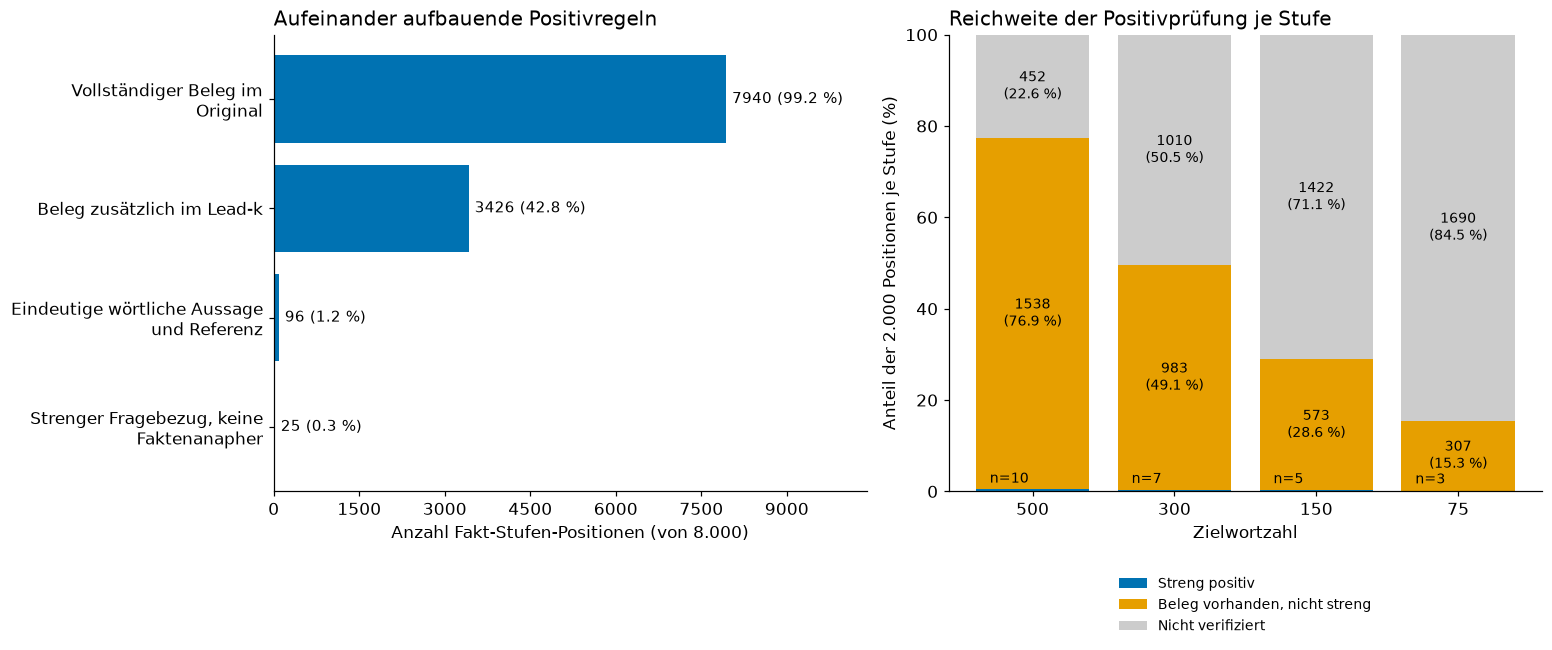

**Beobachtung:** Die strenge Positivregel umfasst 25 von 8000 Fakt-Stufen-Positionen (0,3 %). Darin liegen 0 Positionen ohne Retained. Die Erkennungsrate ist daher immer zusammen mit der Größe und Auswahl dieser Teilmenge zu lesen.

In [14]:
import textwrap
fig,(ax,bx)=plt.subplots(1,2,figsize=(14,5.8),layout='constrained')
labels=['Vollständiger Beleg im Original','Beleg zusätzlich im Lead-k',
        'Eindeutige wörtliche Aussage und Referenz','Strenger Fragebezug, keine Faktenanapher']
ax.barh(range(4),filter_counts.n_positionen,color='#0072B2')
for j,r in enumerate(filter_counts.itertuples()):
    ax.text(r.n_positionen+100,j,f'{r.n_positionen} ({100*r.n_positionen/len(qa):.1f} %)',va='center',fontsize=10)
ax.set(yticks=range(4),yticklabels=['\n'.join(textwrap.wrap(s,29)) for s in labels],
       xlim=(0,len(qa)*1.30),xlabel='Anzahl Fakt-Stufen-Positionen (von 8.000)',title='Aufeinander aufbauende Positivregeln')
ax.invert_yaxis();ax.xaxis.set_major_locator(MaxNLocator(integer=True))
bottom=np.zeros(4)
category_labels={'strict_positive':'Streng positiv','ambiguous':'Beleg vorhanden, nicht streng','not_verified':'Nicht verifiziert'}
for category,color in zip(category_labels,['#0072B2','#E69F00','#CCCCCC']):
    counts=category_counts[category].to_numpy()
    values=100*counts/category_counts.Gesamt.to_numpy()
    bx.bar(range(4),values,bottom=bottom,color=color,label=category_labels[category])
    for j,(value,count) in enumerate(zip(values,counts)):
        if value>=5:bx.text(j,bottom[j]+value/2,f'{int(count)}\n({value:.1f} %)',ha='center',va='center',fontsize=9)
        elif count:bx.annotate(f'n={int(count)}',(j,bottom[j]+value/2),xytext=(-28,5),textcoords='offset points',fontsize=9)
    bottom+=values
assert np.allclose(bottom,100)
bx.set(xticks=range(4),xticklabels=STAGES,ylim=(0,100),xlabel='Zielwortzahl',ylabel='Anteil der 2.000 Positionen je Stufe (%)',title='Reichweite der Positivprüfung je Stufe')
bx.legend(loc='upper center',bbox_to_anchor=(.5,-.16),frameon=False,fontsize=9)
save_figure(fig,'D_selektion_und_abdeckung_des_positivtests')
display(Markdown(f'**Beobachtung:** Die strenge Positivregel umfasst {int(qa.strict_positive.sum())} von '
    f'{len(qa)} Fakt-Stufen-Positionen ({de(100*qa.strict_positive.mean())} %). '
    f'Darin liegen {len(strict_failures)} Positionen ohne Retained. Die Erkennungsrate ist daher '
    'immer zusammen mit der Größe und Auswahl dieser Teilmenge zu lesen.'))


## 6. Statistische Unsicherheit

10.000 nichtparametrische Cluster-Bootstrap-Ziehungen aus den **100 Artikeln**, Seed 32.
Alle Fragen und Stufen eines gezogenen Artikels bleiben zusammen. Artikel ohne positive
Fälle tragen Nullzählungen bei. Für die PDR wird in jeder Ziehung das Verhältnis der
gepoolten Zähler und Nenner neu berechnet, kein Mittel von Artikelquoten. Die primäre
und die Sensitivitätsrate verwenden dieselben Ziehungen. Berichtet werden punktweise
95-%-Perzentilintervalle und die Zahl der Artikel mit Nennerbeitrag.

Mindestens zwei beitragende Artikel und ein positiver Nenner sind für ein Intervall
erforderlich. Weniger als 30 beitragende Artikel werden ausdrücklich markiert;
30 ist eine Darstellungshilfe, keine formale Gütegrenze. Nullnenner-Ziehungen bleiben
als fehlend dokumentiert. Ein Intervall [100 %, 100 %] bei ausschließlich erkannten
Positivfällen zeigt die Degeneration des empirischen Bootstraps, keine garantierte
fehlerfreie Population. Unsicherheit über die semantische Validität der Referenzen,
Fragen und Positivselektion wird nicht durch diese Intervalle erfasst.

In [15]:
rng = np.random.default_rng(SEED)
draws = rng.integers(0,len(IDS),size=(BOOTSTRAPS,len(IDS)))
weights = np.zeros((BOOTSTRAPS,len(IDS)),dtype=np.int16)
np.add.at(weights,(np.repeat(np.arange(BOOTSTRAPS),len(IDS)),draws.ravel()),1)
assert np.all(weights.sum(axis=1)==len(IDS))

def cluster_ratio(frame, numerator, denominator):
    grouped = frame.assign(_num=np.asarray(numerator,dtype=int), _den=np.asarray(denominator,dtype=int)).groupby('article_id')[['_num','_den']].sum().reindex(IDS,fill_value=0)
    counts = grouped.to_numpy(dtype=float)
    n,d = counts.sum(axis=0)
    boot_counts = weights @ counts
    boot = np.divide(boot_counts[:,0],boot_counts[:,1],out=np.full(BOOTSTRAPS,np.nan),where=boot_counts[:,1]>0)
    contributors = int((counts[:,1]>0).sum())
    enough = contributors>=2 and d>0 and np.isfinite(boot).sum()>0
    low,high = np.nanquantile(boot,[.025,.975]) if enough else [np.nan,np.nan]
    return {'n_numerator':int(n),'n_denominator':int(d),'n_articles_denominator':contributors,
            'estimate_percent':percent(n,d),'ci_low_percent':100*low,'ci_high_percent':100*high,
            'bootstrap_zero_denominator':int(np.isnan(boot).sum()),
            'small_article_group':contributors<30,
            'empirical_degenerate':bool(enough and np.nanmin(boot)==np.nanmax(boot))}

ci_rows = []
for scope in ['Gesamt']+STAGES:
    sub = qa[qa.strict_positive] if scope=='Gesamt' else qa[qa.strict_positive & qa.stage_target_words.eq(scope)]
    for policy, den in [('gültige_strenge_Positive',sub.valid),('alle_strengen_Positive',np.ones(len(sub),dtype=bool))]:
        ci_rows.append({'Kennzahl':'Positive Detection Rate','Stufe':str(scope),'Nennerregel':policy,
                        **cluster_ratio(sub,sub.label.eq('retained'),den)})
ci_detection = pd.DataFrame(ci_rows)
display(ci_detection.round(2))
export(ci_detection,'pdr_artikelbootstrap_10000_seed32')
path_frame = paths.reset_index()
ci_monotony = pd.DataFrame([{'Kennzahl':'Betroffene Faktenverläufe (benachbart)',
    **cluster_ratio(path_frame,path_frame.violation_adjacent,path_frame.eligible_adjacent)}])
export(ci_monotony,'monotonie_artikelbootstrap_10000_seed32')
display(ci_monotony.round(2))


,Kennzahl,Stufe,Nennerregel,n_numerator,n_denominator,n_articles_denominator,estimate_percent,ci_low_percent,ci_high_percent,bootstrap_zero_denominator,small_article_group,empirical_degenerate
0,Positive Detection Rate,Gesamt,gültige_strenge_Positive,25,25,10,100.0,100.0,100.0,0,True,True
1,Positive Detection Rate,Gesamt,alle_strengen_Positive,25,25,10,100.0,100.0,100.0,0,True,True
2,Positive Detection Rate,500,gültige_strenge_Positive,10,10,10,100.0,100.0,100.0,0,True,True
3,Positive Detection Rate,500,alle_strengen_Positive,10,10,10,100.0,100.0,100.0,0,True,True
4,Positive Detection Rate,300,gültige_strenge_Positive,7,7,7,100.0,100.0,100.0,9,True,True
5,Positive Detection Rate,300,alle_strengen_Positive,7,7,7,100.0,100.0,100.0,9,True,True
6,Positive Detection Rate,150,gültige_strenge_Positive,5,5,5,100.0,100.0,100.0,66,True,True
7,Positive Detection Rate,150,alle_strengen_Positive,5,5,5,100.0,100.0,100.0,66,True,True
8,Positive Detection Rate,75,gültige_strenge_Positive,3,3,3,100.0,100.0,100.0,479,True,True
9,Positive Detection Rate,75,alle_strengen_Positive,3,3,3,100.0,100.0,100.0,479,True,True


,Kennzahl,n_numerator,n_denominator,n_articles_denominator,estimate_percent,ci_low_percent,ci_high_percent,bootstrap_zero_denominator,small_article_group,empirical_degenerate
0,Betroffene Faktenverläufe (benachbart),22,1999,100,1.1,0.7,1.55,0,False,False


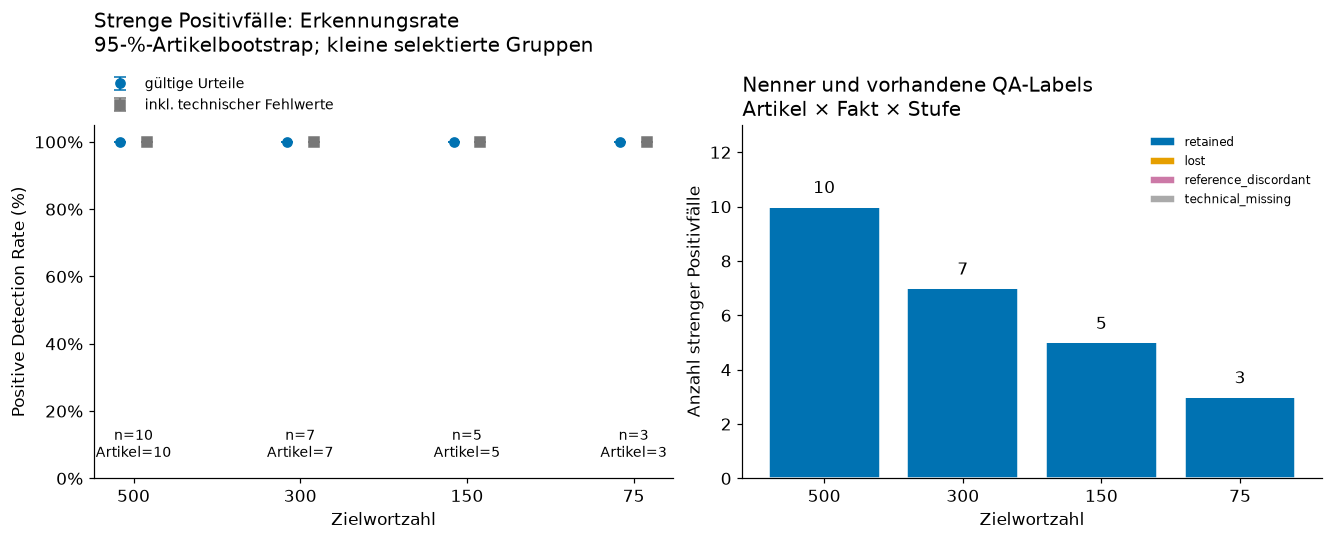

In [16]:
fig, axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
ax,bx = axes
stage_ci = ci_detection[ci_detection.Stufe.ne('Gesamt')]
for shift,policy,label,marker,color in [(-.08,'gültige_strenge_Positive','gültige Urteile','o','#0072B2'),
                                       (.08,'alle_strengen_Positive','inkl. technischer Fehlwerte','s','#777777')]:
    rows = stage_ci[stage_ci.Nennerregel.eq(policy)].set_index('Stufe').reindex([str(k) for k in STAGES])
    y = rows.estimate_percent.to_numpy(dtype=float)
    ax.errorbar(np.arange(4)+shift,y,yerr=np.vstack([y-rows.ci_low_percent.to_numpy(dtype=float),
                       rows.ci_high_percent.to_numpy(dtype=float)-y]),fmt=marker,linestyle='none',
                color=color,capsize=4,label=label)
ax.set(xticks=range(4),xticklabels=STAGES,ylim=(0,105),xlabel='Zielwortzahl',ylabel='Positive Detection Rate (%)')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_title('Strenge Positivfälle: Erkennungsrate\n95-%-Artikelbootstrap; kleine selektierte Gruppen',pad=48)
ax.legend(loc='lower left',bbox_to_anchor=(0,1.0),frameon=False,fontsize=9)
stage_n = detection.set_index('Stufe').loc[[str(k) for k in STAGES]]
for x,r in enumerate(stage_n.itertuples()):
    ax.text(x,5,f'n={r.n_positive}\nArtikel={r.n_articles}',ha='center',va='bottom',fontsize=9)
bottom = np.zeros(4)
for label in LABELS:
    vals = qa[qa.strict_positive].groupby(['stage_target_words','label']).size().unstack(fill_value=0).reindex(STAGES,fill_value=0)
    heights = vals[label].to_numpy() if label in vals else np.zeros(4)
    bx.bar(range(4),heights,bottom=bottom,color=COLORS[label],label=label,edgecolor='white')
    bottom += heights
for x,n in enumerate(bottom): bx.text(x,n+.5,str(int(n)),ha='center')
bx.set(xticks=range(4),xticklabels=STAGES,xlabel='Zielwortzahl',ylabel='Anzahl strenger Positivfälle')
bx.yaxis.set_major_locator(MaxNLocator(integer=True))
bx.set_ylim(0,max(1,max(bottom))*1.3)
bx.set_title('Nenner und vorhandene QA-Labels\nArtikel × Fakt × Stufe')
bx.legend(loc='upper right',frameon=False,fontsize=8)
save_figure(fig,'B_positive_detection_rate_und_fallzahlen')


## 7. Zusammenfassung der wichtigsten Ergebnisse

Die folgende Übersicht wird aus den ausgeführten Berechnungen erzeugt. Die engen
und breiten Textnachweisgruppen werden nebeneinander ausgewiesen, damit eine hohe
Erkennungsrate der strengen Teilmenge nicht die übrigen Befunde verdeckt.

In [17]:
overall = detection[detection.Stufe.eq('Gesamt')].iloc[0]
overall_ci = ci_detection[(ci_detection.Stufe=='Gesamt') & (ci_detection.Nennerregel=='gültige_strenge_Positive')].iloc[0]
broad = sensitivity[(sensitivity.Stufe=='Gesamt') & (sensitivity.Gruppe=='vollstaendiger_Beleg')].iloc[0]
summary_rows = [
    ['Monotonie: betroffene Faktenverläufe',f'{n_bad}/{int(paths.eligible_adjacent.sum())}',f'{de(percent(n_bad,paths.eligible_adjacent.sum()),2)} %'],
    ['Monotonie: widersprüchliche benachbarte Übergänge',str(int(adjacent.violation.sum())),'10/9/4 nur falls aus den Daten bestätigt'],
    ['Monotonie: betroffene Artikel',f'{n_affected_articles}/100',f'{de(n_affected_articles)} %'],
    ['Historisch gezählte Rückkehrverläufe',str(int(paths.historical_counted_return.sum())),'Definition: erste Nicht-R-Stufe bestimmbar'],
    ['Strenge Positivpositionen / eindeutige Fakten',f'{overall.n_positive} / {overall.n_distinct_facts}',f'{overall.n_articles} Artikel'],
    ['PDR, nur gültige strenge Fälle',f'{overall.n_retained}/{overall.n_valid}',f'{de(overall.PDR_percent,2)} %'],
    ['PDR, einschließlich technischer Fehlwerte',f'{overall.n_retained}/{overall.n_positive}',f'{de(overall.PDR_all_percent,2)} %'],
    ['Strenge Fälle: technische Fehlwerte',str(overall.n_technical_missing),'kein inhaltliches Verlustlabel'],
    ['Breiter vollständiger Textbeleg: Retained-Anteil',f'{broad.n_retained}/{broad.n_valid}',f'{de(broad.retained_Anteil_valid_percent,2)} %; kein gesicherter Recall'],
]
summary_table = pd.DataFrame(summary_rows,columns=['Befund','Zähler / Nenner bzw. Anzahl','Einordnung'])
summary_table.loc[1,'Einordnung'] = '; '.join(f'{r.transition}: {r.n_violations}' for r in transition_summary.itertuples())
display(summary_table)
export(summary_table,'wichtigste_ergebnisse')
display(Markdown(f'Die strenge Gruppe umfasst nur {de(percent(overall.n_positive,8000),2)} % der 8.000 QA-Positionen. '
    'Ihre Auswahl bevorzugt vollständig wörtliche und lexikalisch leicht zuzuordnende Aussagen. '
    'Der beobachtete bedingte Recall ist deshalb kein belastbarer Nachweis hoher Zuverlässigkeit '
    'für alle Lead-k-Fakten oder für abstraktive Summaries.'))


,Befund,Zähler / Nenner bzw. Anzahl,Einordnung
0,Monotonie: betroffene Faktenverläufe,22/1999,"1,10 %"
1,Monotonie: widersprüchliche benachbarte Übergänge,23,500→300: 10; 300→150: 9; 150→75: 4
2,Monotonie: betroffene Artikel,21/100,"21,0 %"
3,Historisch gezählte Rückkehrverläufe,21,Definition: erste Nicht-R-Stufe bestimmbar
4,Strenge Positivpositionen / eindeutige Fakten,25 / 10,10 Artikel
5,"PDR, nur gültige strenge Fälle",25/25,"100,00 %"
6,"PDR, einschließlich technischer Fehlwerte",25/25,"100,00 %"
7,Strenge Fälle: technische Fehlwerte,0,kein inhaltliches Verlustlabel
8,Breiter vollständiger Textbeleg: Retained-Anteil,3275/3416,"95,87 %; kein gesicherter Recall"


Die strenge Gruppe umfasst nur 0,31 % der 8.000 QA-Positionen. Ihre Auswahl bevorzugt vollständig wörtliche und lexikalisch leicht zuzuordnende Aussagen. Der beobachtete bedingte Recall ist deshalb kein belastbarer Nachweis hoher Zuverlässigkeit für alle Lead-k-Fakten oder für abstraktive Summaries.

## 8. Limitationen

- Lead-k enthält überwiegend wörtliche Übernahmen. Befunde sind nicht unmittelbar auf
  abstraktive Zusammenfassungen mit Paraphrasen übertragbar.
- Die Monotonieprüfung entdeckt Inkonsistenzen, nicht sämtliche Fehlklassifikationen.
  Sie entscheidet nicht, welches Urteil falsch ist, und misst keine allgemeine
  False-Positive- oder False-Negative-Rate. Fragegültigkeit, Mehrdeutigkeit und
  Kontextabhängigkeit bleiben relevant.
- Belege, Fakten, Fragen und Referenzen wurden automatisch erzeugt. Selbst die strenge
  Textkontrolle liefert ohne unabhängige Prüfung keine vollständig unabhängige Ground Truth.
  Die zusätzliche wörtliche Fakten- und Fragebedingung schränkt die Fallzahl stark ein
  und kann besonders einfache Fälle auswählen; ein hoher Wert ist entsprechend selektiv.
- Ein nicht im Präfix gefundener Originalbeleg beweist keine Unbeantwortbarkeit:
  andere Textstellen oder Formulierungen können dieselbe Information tragen.
  `ambiguous` und `not_verified` dürfen deshalb nicht zu negativen Referenzfällen werden.
- Bootstrap-Intervalle beschreiben Artikelheterogenität bei gegebenen Labels und
  Selektionsregeln. Sie enthalten keine Unsicherheit über die Label-/Referenzrichtigkeit,
  keine Modellneugenerierung und keine Korrektur für Mehrfachvergleiche. Wiederholte
  Stufen desselben Faktums sind keine unabhängigen Positivbeobachtungen.
- Die gespeicherten finalen Antworten und Belege erlauben nur begrenzte Ursachendiagnosen.
  Semantisch korrekte Antworten mit abgelehntem Referenzabgleich sind ohne unabhängige
  Inhaltsbewertung nicht als Token-F1-Fehler nachgewiesen. Eine Null in einer nicht
  identifizierbaren Ursachenklasse bedeutet **keine** nachgewiesene Fehlerfreiheit.
- Es wird keine globale Korrektur der Faktenretentionswerte abgeleitet und kein
  bestehendes QA-Label umklassifiziert. Die Resultate sind zusätzliche interne
  Konsistenz- und Positivkontrollen, kein Ersatz für unabhängige Human Validation.

## 9. Übertragbare Ergebnisse für die Masterarbeit

### Wissenschaftlich relevante Ergebnisse für Kapitel 4.1

Der folgende Text wird automatisch aus den Daten erzeugt (maximal 300 Wörter).
Er trennt Messung, Interpretation und verbleibende offene Fragen.

In [18]:
chapter = (
    f'Die interne Qualitätskontrolle umfasste 2.000 Lead-k-Faktenverläufe aus 100 Artikeln '
    f'auf vier Kompressionsstufen. Alle 400 gespeicherten Texte erfüllten die implementierte '
    f'Präfixregel. {int(paths.complete.sum())} Verläufe waren vollständig auswertbar. '
    f'Unter {int(paths.eligible_adjacent.sum())} Verläufen mit auswertbaren benachbarten Paaren '
    f'zeigten {n_bad} ({de(percent(n_bad,paths.eligible_adjacent.sum()),2)} %) mindestens einen '
    f'Rückwechsel von nicht retained zu retained. Die {int(adjacent.violation.sum())} widersprüchlichen '
    f'Übergänge verteilten sich auf {n_affected_articles} Artikel. Die bisher berichteten 21 Fälle '
    f'{"ließen sich" if reported_21_reproduced else "ließen sich nicht"} unter der historischen '
    f'Auswahlregel reproduzieren; die Paarprüfung berücksichtigt zusätzlich Widersprüche '
    f'in technisch unvollständigen Verläufen.\n\n'
    f'Der konservative Positivtest identifizierte {overall.n_positive} streng textbelegte '
    f'Artikel-Fakt-Stufen-Kombinationen ({overall.n_distinct_facts} unterschiedliche Fakten; '
    f'{overall.n_articles} Artikel). Davon waren {overall.n_valid} auswertbar und '
    f'{overall.n_retained} retained. Der bedingte Recall betrug {de(overall.PDR_percent,2)} % '
    f'(95-%-Artikelbootstrap-Intervall: {de(overall_ci.ci_low_percent,2)}–{de(overall_ci.ci_high_percent,2)} %; '
    f'10.000 Ziehungen, Seed 32). Einschließlich technischer Fehlwerte im Nenner ergaben sich '
    f'{de(overall.PDR_all_percent,2)} %. Die strenge Auswahl erfasst nur '
    f'{de(percent(overall.n_positive,8000),2)} % aller QA-Positionen; der Wert ist keine globale Recall-Schätzung. '
    'Das degenerierte empirische Intervall erfasst keine ungesehenen Fehler.\n\n'
    'Die Widersprüche begrenzen die bisherige QA-Validierung. Eine hohe Erkennung der engen '
    'wörtlichen Teilmenge kann diese Grenze nicht aufheben. Empfohlen werden die Übergangstabelle '
    'und ergänzend die PDR-Tabelle mit Fallzahlen und Artikelintervallen. Offen bleiben die '
    'unabhängige semantische Qualität von Fragen und Belegen, die Richtigkeit widersprüchlicher '
    'Einzelurteile sowie die Übertragbarkeit auf abstraktive Zusammenfassungen. Die Ergebnisse '
    'begründen zusätzliche Humanvalidierung, keine nachträgliche Labelkorrektur.'
)
assert len(chapter.split()) <= 300, len(chapter.split())
(OUT/'Wissenschaftlich_relevante_Ergebnisse_Kapitel_4_1.md').write_text(chapter+'\n',encoding='utf-8')
display(Markdown(chapter))
display(Markdown(f'*Automatisch erzeugter Text: {len(chapter.split())} Wörter.*'))


Die interne Qualitätskontrolle umfasste 2.000 Lead-k-Faktenverläufe aus 100 Artikeln auf vier Kompressionsstufen. Alle 400 gespeicherten Texte erfüllten die implementierte Präfixregel. 1991 Verläufe waren vollständig auswertbar. Unter 1999 Verläufen mit auswertbaren benachbarten Paaren zeigten 22 (1,10 %) mindestens einen Rückwechsel von nicht retained zu retained. Die 23 widersprüchlichen Übergänge verteilten sich auf 21 Artikel. Die bisher berichteten 21 Fälle ließen sich unter der historischen Auswahlregel reproduzieren; die Paarprüfung berücksichtigt zusätzlich Widersprüche in technisch unvollständigen Verläufen.

Der konservative Positivtest identifizierte 25 streng textbelegte Artikel-Fakt-Stufen-Kombinationen (10 unterschiedliche Fakten; 10 Artikel). Davon waren 25 auswertbar und 25 retained. Der bedingte Recall betrug 100,00 % (95-%-Artikelbootstrap-Intervall: 100,00–100,00 %; 10.000 Ziehungen, Seed 32). Einschließlich technischer Fehlwerte im Nenner ergaben sich 100,00 %. Die strenge Auswahl erfasst nur 0,31 % aller QA-Positionen; der Wert ist keine globale Recall-Schätzung. Das degenerierte empirische Intervall erfasst keine ungesehenen Fehler.

Die Widersprüche begrenzen die bisherige QA-Validierung. Eine hohe Erkennung der engen wörtlichen Teilmenge kann diese Grenze nicht aufheben. Empfohlen werden die Übergangstabelle und ergänzend die PDR-Tabelle mit Fallzahlen und Artikelintervallen. Offen bleiben die unabhängige semantische Qualität von Fragen und Belegen, die Richtigkeit widersprüchlicher Einzelurteile sowie die Übertragbarkeit auf abstraktive Zusammenfassungen. Die Ergebnisse begründen zusätzliche Humanvalidierung, keine nachträgliche Labelkorrektur.

*Automatisch erzeugter Text: 197 Wörter.*

### Abschlussprüfung und Ausgabeverzeichnis

Zum Abschluss werden Quellenhashes erneut geprüft und alle Zählungen abgestimmt.
Die Notebookausführung protokolliert Software, Definitionen, Seed und Datenstand.
Die Quelldateien wurden nur gelesen. CSV-Dateien enthalten ausschließlich neue
Analyseergebnisse oder unverändert übernommene Ausgangsfelder; manuelle Urteilsfelder
in der Kontrollstichprobe sind leer.

In [19]:
assert len(qa)==8000 and len(paths)==2000
assert qa.positive_category.value_counts().sum()==8000
assert category_counts['Gesamt'].sum()==8000
assert transition_summary.n_violations.sum()==len(adjacent[adjacent.violation])
# Unabhängige Mengenzählung der Rückwechsel aus den archivierten Labels.
direct_rows = archived.set_index(KEY)
independent_bad = set()
independent_events = 0
for fact in facts.itertuples():
    for before,after in zip(STAGES[:-1],STAGES[1:]):
        left = direct_rows.loc[(fact.article_id,fact.canonical_fact_id,before)]
        right = direct_rows.loc[(fact.article_id,fact.canonical_fact_id,after)]
        if left.technical_missing=='False' and right.technical_missing=='False' and left.retention=='False' and right.retention=='True':
            independent_bad.add((fact.article_id,fact.canonical_fact_id))
            independent_events += 1
assert len(independent_bad)==n_bad and independent_events==int(adjacent.violation.sum())
for source,digest in sources_before.items():
    assert hashlib.sha256(Path(source).read_bytes()).hexdigest()==digest, source
assert manual_review.filter(regex='^human_|^reviewer_').eq('').all().all()
run_manifest = {
    'version':VERSION,'seed':SEED,'bootstrap_samples':BOOTSTRAPS,'resampling_unit':'article',
    'source_package':str(PACKAGE),'source_files_unchanged':True,'existing_qa_labels_changed':False,
    'new_llm_calls':0,'summary_generation':False,'n_articles':100,'n_facts':2000,'n_qa_positions':8000,
    'n_complete_paths':int(paths.complete.sum()),'n_technical_missing':int((~qa.valid).sum()),
    'n_adjacent_events':independent_events,'n_adjacent_affected_paths':n_bad,
    'n_all_pairs_affected_paths':n_bad_all,'n_affected_articles':n_affected_articles,
    'historical_21_reproduced':reported_21_reproduced,
    'n_historical_counted_return':int(paths.historical_counted_return.sum()),
    'n_strict_positive':int(overall.n_positive),'n_strict_valid':int(overall.n_valid),
    'n_strict_retained':int(overall.n_retained),'pdr_percent':float(overall.PDR_percent),
    'pdr_all_percent':float(overall.PDR_all_percent),'software':software,
    'source_manifest_sha256':sources_before[str(manifest_path)],
    'positive_reference':'operational strict textual subset; no independent human ground truth',
}
(OUT/'ausfuehrungsprotokoll.json').write_text(json.dumps(run_manifest,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
display(Markdown('**Abgeschlossen:** Alle Eingabe-, Präfix-, Schlüssel-, Nenner- und Quellenprüfungen erfolgreich. '
                 'Bestehende Daten, QA-Klassifikationen und Notebooks unverändert.'))
files = pd.DataFrame([{'Datei':str(p.relative_to(ROOT)), 'Bytes':p.stat().st_size}
                       for p in sorted(OUT.rglob('*')) if p.is_file()])
display(files)


**Abgeschlossen:** Alle Eingabe-, Präfix-, Schlüssel-, Nenner- und Quellenprüfungen erfolgreich. Bestehende Daten, QA-Klassifikationen und Notebooks unverändert.

,Datei,Bytes
0,Wissenschaftlich_relevante_Ergebnisse_Kapitel_...,1732
1,abgleich_21_definitionen.csv,327
2,alle_faktenverlaeufe.csv,137815
3,ambiguous_pruefhinweise_KEINE_bestaetigten_feh...,3431
4,ausfuehrungsprotokoll.json,1162
...,...,...
30,textnachweis_sensitivitaeten_keine_globale_rec...,2464
31,unveraenderte_qa_labels_anzahlen.csv,147
32,wichtigste_ergebnisse.csv,678
33,widerspruechliche_stufenpaare.csv,21641
